# RRUFF Raman RAW, confirmed: what the seven archives hold

Seven RRUFF Raman archives sit under `~/Desktop/raman_data`, one directory per archive.
`LR-Raman` is in that directory too and is not read here: it is the low-resolution broad
scan rather than one of the quality and orientation archives.

Every export in the seven is read. The notebook keeps those whose `FILETYPE` is
`Raman RAW` and whose `STATUS` records a confirmed identification, then measures what is
left: the wavelength range and spacing, the number of points, the distribution of the
classes (the minerals), the distribution of the excitation wavelength, the duplication
between the RAW and Processed exports of one measurement, the coverage across archives,
and the intensity scale.

Apart from the window decision the last section records, it reports what the files hold
and draws no conclusions from any of it.

## 1. Setting up

The archives are looked for under `~/Desktop/raman_data` unless `RRUFF_DATA` points
somewhere else, so the notebook runs unchanged from another checkout.

In [1]:
from __future__ import annotations

import os
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

# Categorical slots are taken in a fixed order and never cycled.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "text.color": INK,
    "font.size": 9,
    "legend.frameon": False,
    "figure.dpi": 110,
})

# The seven archives read here, LR-Raman left out.
ARCHIVES = [
    "excellent_oriented",
    "excellent_unoriented",
    "fair_oriented",
    "fair_unoriented",
    "poor_unoriented",
    "unrated_oriented",
    "unrated_unoriented",
]

# RRUFF_DATA points the notebook at another extraction of the same archives.
DATA_ROOT = Path(os.environ.get("RRUFF_DATA", Path.home() / "Desktop" / "raman_data")).expanduser()

# Used by the reader below, which is why they are module level rather than inside it.
HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")
NUMBER = re.compile(r"[0-9]+(?:\.[0-9]+)?")
LEADING = "+-."

absent = [name for name in ARCHIVES if not (DATA_ROOT / name).is_dir()]
if absent:
    raise FileNotFoundError(f"these archive directories are missing under {DATA_ROOT}: {absent}")

print(f"reading {len(ARCHIVES)} archives from {DATA_ROOT}")
for name in ARCHIVES:
    print(f"  {name:22s} {len(list((DATA_ROOT / name).glob('*.txt'))):6,d} files")

reading 7 archives from /home/raj/Desktop/raman_data
  excellent_oriented      7,668 files
  excellent_unoriented   11,415 files
  fair_oriented              25 files
  fair_unoriented         2,951 files
  poor_unoriented         1,639 files
  unrated_oriented        3,778 files
  unrated_unoriented        639 files


## 2. Reading one export

A file is a `##KEY=value` block, then the data rows, then usually a `##END=` line after the
last one. Three things about that block defeat a reader that stops at the first line not
starting with `##`:

- a value can wrap onto the following line, which then carries no `##` of its own, so a
  pin's fiducial note ends up on the wavelength's line;
- the block can repeat, so a later key has to overwrite an earlier one;
- the exports carry `#`-prefixed notes between the block and the data.

So the block runs to the first data row, and any other stray line is a continuation of the
key above it. Stopping at the first non-`##` line instead loses `FILETYPE` on 492 files of
these archives, every one of them in `excellent_oriented`, and `RAMAN WAVELENGTH` on 501
across three archives. Losing `FILETYPE` is what matters here: without that field a file
cannot be told a RAW export from a Processed one.

A data row is exactly two numbers, which is what separates it from a continuation that
happens to begin with a digit. Text is decoded as UTF-8, which is what RRUFF writes; a few
files carry a stray latin-1 byte inside a comment, so undecodable bytes are replaced rather
than raising. Lines are split on newline alone: `str.splitlines()` also breaks on the
control characters that occur inside a few locality names.

In [2]:
def read_spectrum(path):
    """Read one export: its header fields, and facts about its data block.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: the header fields as a dict, and a dict describing the data block with the
        keys points, x_min, x_max, wrapped_values, repeated_keys, comment_notes,
        separator, crlf and encoding.
    """
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8")
        encoding = "utf-8"
    except UnicodeDecodeError:
        text = raw.decode("utf-8", errors="replace")
        encoding = "utf-8, one byte replaced"
    text = text.replace("\r\n", "\n")
    lines = text.split("\n")

    header, last = {}, None
    wrapped = repeated = notes = 0
    separator = ""
    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is None:
                notes += 1
                continue
            key, value = match.group(1).strip(), match.group(2).strip()
            if key == "END":
                body = position + 1
                break
            if key in header:
                repeated += 1
            header[key] = value
            last = key
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    separator = ("tab" if "\t" in line
                                 else "comma" if "," in line else "space")
                    break
        if last is not None:
            header[last] = header[last] + " " + stripped
            wrapped += 1

    points, first_row, last_row = 0, None, None
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped:
            continue
        if stripped.startswith("##END"):
            break
        if stripped[0] == "#":
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            points += 1
            if first_row is None:
                first_row = stripped
            last_row = stripped

    x_min = float(first_row.replace(",", " ").split()[0]) if first_row else None
    x_max = float(last_row.replace(",", " ").split()[0]) if last_row else None
    if x_min is not None and x_max is not None and x_min > x_max:
        x_min, x_max = x_max, x_min

    layout = {
        "points": points, "x_min": x_min, "x_max": x_max,
        "wrapped_values": wrapped, "repeated_keys": repeated, "comment_notes": notes,
        "separator": separator, "crlf": b"\r\n" in raw,
        "encoding": encoding,
    }
    return header, layout

In [3]:
def read_block_rows(path):
    """The data rows of one export, with the header and any comment lines removed.

    Args:
        path (Path): the export to read.

    Returns:
        list: the stripped lines of the data block, in file order.
    """
    text = path.read_text(encoding="utf-8", errors="replace").replace("\r\n", "\n")
    lines = text.split("\n")

    body = None
    for position, line in enumerate(lines):
        stripped = line.strip()
        if not stripped:
            continue
        if stripped[0] == "#":
            match = HEADER_LINE.match(stripped)
            if match is not None and match.group(1).strip() == "END":
                body = position + 1
                break
            continue
        head = stripped[0]
        if head.isdigit() or head in LEADING:
            fields = stripped.replace(",", " ").split()
            if len(fields) == 2:
                try:
                    float(fields[0])
                    float(fields[1])
                except ValueError:
                    pass
                else:
                    body = position
                    break

    rows = []
    for line in lines[body:] if body is not None else ():
        stripped = line.strip()
        if not stripped or stripped.startswith("#"):
            continue
        rows.append(stripped)
    return rows


def read_values(path):
    """Read the two columns of one export's data block, on the same block rule as above.

    Args:
        path (Path): the export to read.

    Returns:
        list: (wavenumber, intensity) pairs, in file order.
    """
    values = []
    for row in read_block_rows(path):
        fields = row.replace(",", " ").split()
        if len(fields) == 2:
            try:
                values.append((float(fields[0]), float(fields[1])))
            except ValueError:
                pass
    return values

## 3. One row per file

`FILETYPE` gives the export kind, so it is read from that field rather than guessed from
the file name, and the excitation wavelength is taken from whatever number `RAMAN
WAVELENGTH` carries. `measurement` is the file name without its last two fields, the export
kind and the content hash, so two exports of one measurement share it.

In [4]:
started = time.time()
records = []
for archive in ARCHIVES:
    for path in sorted((DATA_ROOT / archive).glob("*.txt")):
        header, layout = read_spectrum(path)
        filetype = header.get("FILETYPE", "")
        found = NUMBER.search(header.get("RAMAN WAVELENGTH", ""))
        records.append({
            "archive": archive,
            "path": str(path),
            "name": path.stem,
            "measurement": "__".join(path.stem.split("__")[:6]),
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            "filetype": filetype,
            "kind": "RAW" if "RAW" in filetype.upper() else "Processed",
            "wavelength_reported": header.get("RAMAN WAVELENGTH", ""),
            "wavelength_nm": float(found.group()) if found else np.nan,
            "status": header.get("STATUS", ""),
            "bytes": path.stat().st_size,
            **layout,
        })

pool = pd.DataFrame.from_records(records)
# How finely a file samples its own range, which is what resampling onto a shared grid has
# to work from. Exact when the grid is uniform, an average when it is not.
pool["spacing"] = (pool.x_max - pool.x_min) / (pool.points - 1).replace(0, np.nan)

print(f"read {len(pool):,} files in {time.time() - started:.1f}s, "
      f"{pool.bytes.sum() / 1e9:.2f} GB of text on disk")
pool[["archive", "mineral", "rruff_id", "kind", "wavelength_nm", "status",
      "points", "x_min", "x_max", "spacing"]].head()

read 28,115 files in 13.2s, 1.10 GB of text on disk


,archive,mineral,rruff_id,kind,wavelength_nm,status,points,x_min,x_max,spacing
0,excellent_oriented,Actinolite,R040063,Processed,514.0,The identification of this mineral has been co...,1076,146.865,1518.526,1.275964
1,excellent_oriented,Actinolite,R040063,RAW,514.0,The identification of this mineral has been co...,1076,146.865,1518.526,1.275964
2,excellent_oriented,Actinolite,R040063,Processed,514.0,The identification of this mineral has been co...,1080,141.323,1518.526,1.276370
3,excellent_oriented,Actinolite,R040063,RAW,514.0,The identification of this mineral has been co...,1080,141.323,1518.526,1.276370
4,excellent_oriented,Actinolite,R040063,Processed,514.0,The identification of this mineral has been co...,1087,131.615,1518.526,1.277082


## 4. The two filters

Every file has to pass both.

- **RAW.** `FILETYPE` is `Raman RAW`, the spectrum as the instrument produced it. Each
  measurement is exported up to twice, once raw and once processed, and the two sit side by
  side in the same archive.
- **Confirmed.** `STATUS` does not say the identification is unconfirmed. The field is a
  sentence naming whatever the identification rests on, so any method counts: X-ray
  diffraction, chemical analysis, electron back-scatter diffraction, NMR, or Raman
  spectroscopy on its own.

In [5]:
# An identification RRUFF records no confirmation for is written as "...is not yet
# confirmed" or as the bare "Unconfirmed". The markers are matched as substrings of the
# sentence so a wording omitting the "yet" is caught too.
UNCONFIRMED_MARKERS = ("not yet confirmed", "not confirmed", "unconfirmed")


def is_unconfirmed(status: str) -> bool:
    """Whether a STATUS sentence records no confirmation of the identification.

    Any method of confirmation counts, so a sentence naming X-ray diffraction, chemical
    analysis, Raman spectroscopy or any other technique returns False.

    Args:
        status (str): The STATUS field of one file, as written.

    Returns:
        bool: True if the sentence says the identification is not confirmed.
    """
    text = status.strip().lower()
    return any(marker in text for marker in UNCONFIRMED_MARKERS)


pool["unconfirmed"] = pool.status.map(is_unconfirmed)

raw = pool.kind == "RAW"
confirmed = ~pool.unconfirmed
kept = pool[raw & confirmed].copy()

table = pd.DataFrame({
    "confirmed": [int((raw & confirmed).sum()), int((~raw & confirmed).sum())],
    "unconfirmed": [int((raw & ~confirmed).sum()), int((~raw & ~confirmed).sum())],
}, index=["RAW", "Processed"])
table["files"] = table.sum(axis=1)
table.loc["all files"] = table.sum()
table = table.astype(int)

print(f"the pool:         {len(pool):8,d} files")
print(f"the kept set:     {len(kept):8,d} files ({len(kept) / len(pool) * 100:.1f}% of the pool)")
print()
print(table.to_string())
print()
print("FILETYPE values in the pool:")
for value, count in pool.filetype.value_counts().items():
    print(f"  {int(count):7,d}  {value!r}")
print()
print("STATUS sentences that record no confirmation, in full:")
for value, count in pool.loc[pool.unconfirmed, "status"].value_counts().items():
    print(f"  {int(count):7,d}  {value!r}")

the pool:           28,115 files
the kept set:       13,154 files (46.8% of the pool)

           confirmed  unconfirmed  files
RAW            13154          954  14108
Processed      13054          953  14007
all files      26208         1907  28115

FILETYPE values in the pool:
   14,108  'Raman RAW'
   14,007  'Raman Processed'

STATUS sentences that record no confirmation, in full:
    1,867  'The identification of this mineral is not yet confirmed'
       40  'Unconfirmed'


## 5. Wavelength range

The range each file covers, and the range the kept set covers as a whole. The exports do not
share one window, so the second cell counts how many files cover each candidate window
instead.

In [6]:
by_archive = kept.groupby("archive").agg(
    files=("path", "size"),
    start_min=("x_min", "min"),
    start_p05=("x_min", lambda s: s.quantile(0.05)),
    start_med=("x_min", "median"),
    end_med=("x_max", "median"),
    end_p95=("x_max", lambda s: s.quantile(0.95)),
    end_max=("x_max", "max"),
).round(2)

print(f"kept files start between {kept.x_min.min():.2f} and {kept.x_min.max():.2f} cm-1")
print(f"kept files end between {kept.x_max.min():.2f} and {kept.x_max.max():.2f} cm-1")
print(f"the whole kept set spans {kept.x_min.min():.2f} to {kept.x_max.max():.2f} cm-1")
print(f"the latest start, {kept.x_min.max():.2f} cm-1, is past the earliest end, "
      f"{kept.x_max.min():.2f} cm-1, so no window is covered by every kept file")
print()
by_archive

kept files start between -117.91 and 2291.80 cm-1
kept files end between 827.90 and 6512.71 cm-1
the whole kept set spans -117.91 to 6512.71 cm-1
the latest start, 2291.80 cm-1, is past the earliest end, 827.90 cm-1, so no window is covered by every kept file



,files,start_min,start_p05,start_med,end_med,end_p95,end_max
archive,,,,,,,
excellent_oriented,3799,15.00,49.35,101.73,1529.10,1572.44,4000.00
excellent_unoriented,5242,-19.93,85.01,93.78,1294.00,1519.11,6512.71
fair_oriented,12,75.96,95.70,157.43,1571.92,1575.01,1578.16
fair_unoriented,1193,9.01,88.14,118.51,1286.27,1367.25,4335.87
poor_unoriented,630,26.29,88.06,108.58,1285.74,1309.31,3456.06
unrated_oriented,1927,40.39,51.44,95.95,1570.38,1579.55,1581.54
unrated_unoriented,351,-117.91,60.33,92.38,1300.66,3549.87,4000.24


the most covered window of 100 cm-1 or more: 
  13,152 files cover 400 to 500 cm-1

widest window that still holds most of the set:
  at least   400 cm-1 wide: 13,152 files (100.0%) cover 400 to 800 cm-1
  at least   600 cm-1 wide: 13,150 files (100.0%) cover 400 to 1000 cm-1
  at least   800 cm-1 wide: 13,091 files ( 99.5%) cover 300 to 1100 cm-1
  at least 1,000 cm-1 wide: 12,576 files ( 95.6%) cover 200 to 1200 cm-1
  at least 1,200 cm-1 wide:  5,629 files ( 42.8%) cover 200 to 1400 cm-1


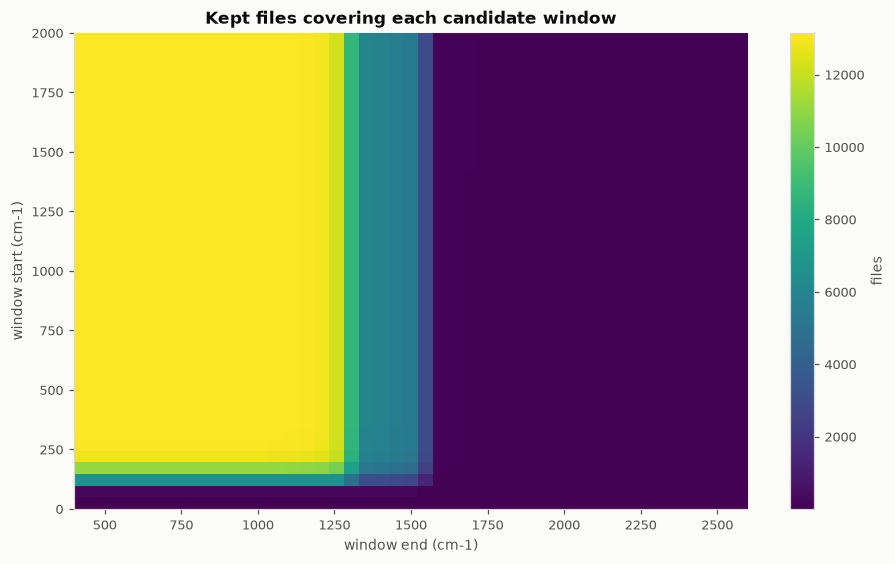

In [7]:
# How many kept files cover a candidate window, over a grid of start and end points. Since
# no window is common to all of them, what a shared window can hold is read off this grid:
# cover[i, j] is the number of files whose range contains [lows[i], highs[j]].
lows = np.arange(0, 2001, 50)
highs = np.arange(400, 2601, 50)
start = kept.x_min.values[:, None, None]
end = kept.x_max.values[:, None, None]
cover = ((start <= lows[None, :, None]) & (end >= highs[None, None, :])).sum(axis=0)

print(f"the most covered window of 100 cm-1 or more: ")
allowed = (highs[None, :] - lows[:, None]) >= 100
masked = np.where(allowed, cover, -1)
i, j = np.unravel_index(masked.argmax(), masked.shape)
print(f"  {int(masked[i, j]):,} files cover {lows[i]:.0f} to {highs[j]:.0f} cm-1")
print()
print("widest window that still holds most of the set:")
for width in (400, 600, 800, 1000, 1200):
    allowed = (highs[None, :] - lows[:, None]) >= width
    masked = np.where(allowed, cover, -1)
    i, j = np.unravel_index(masked.argmax(), masked.shape)
    share = masked[i, j] / len(kept) * 100
    print(f"  at least {width:5,d} cm-1 wide: {int(masked[i, j]):6,d} files "
          f"({share:5.1f}%) cover {lows[i]:.0f} to {highs[j]:.0f} cm-1")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
image = ax.imshow(cover, origin="lower", aspect="auto", cmap="viridis",
                  extent=[highs[0], highs[-1], lows[0], lows[-1]])
ax.set_xlabel("window end (cm-1)")
ax.set_ylabel("window start (cm-1)")
ax.set_title("Kept files covering each candidate window")
ax.grid(False)
fig.colorbar(image, ax=ax, label="files")
plt.tight_layout()
plt.show()

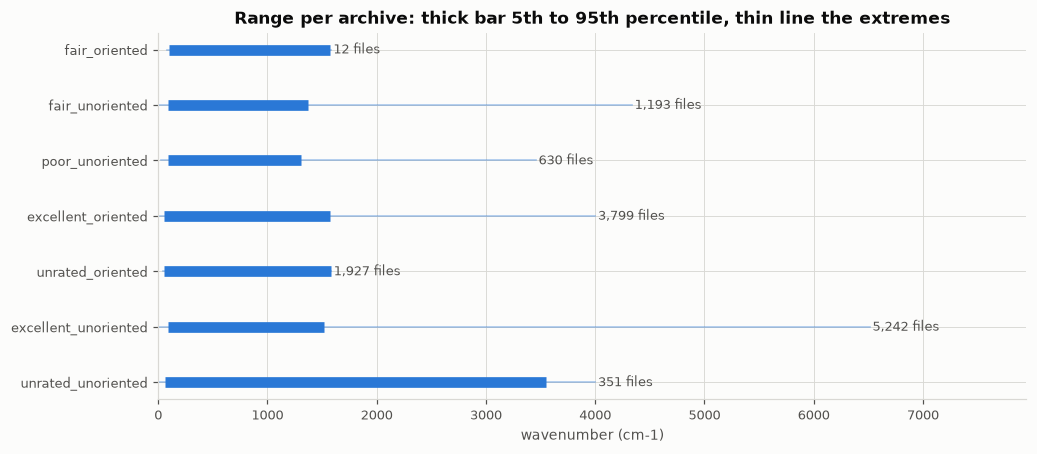

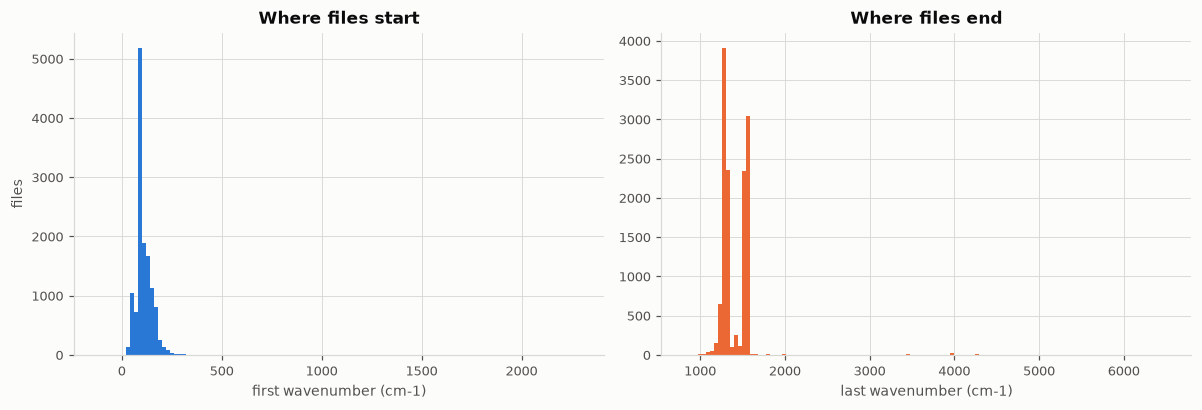

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
order = by_archive.sort_values("start_med").index
for y, name in enumerate(order):
    row = by_archive.loc[name]
    ax.plot([row.start_min, row.end_max], [y, y], color=BLUE, lw=1.1, alpha=0.40)
    ax.plot([row.start_p05, row.end_p95], [y, y], color=BLUE, lw=7, solid_capstyle="butt")
    ax.text(row.end_max + 25, y, f"{row.files:,.0f} files", va="center", fontsize=8.5, color=INK_SOFT)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlim(0, kept.x_max.max() * 1.22)
ax.set_xlabel("wavenumber (cm-1)")
ax.set_title("Range per archive: thick bar 5th to 95th percentile, thin line the extremes")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(kept.x_min, bins=120, color=BLUE)
axes[0].set_title("Where files start")
axes[0].set_xlabel("first wavenumber (cm-1)")
axes[0].set_ylabel("files")
axes[1].hist(kept.x_max, bins=120, color=ORANGE)
axes[1].set_title("Where files end")
axes[1].set_xlabel("last wavenumber (cm-1)")
plt.tight_layout()
plt.show()

## 6. What each archive's files cover along the shift

Section 5 gives each archive's range. This section gives the coverage inside that range: how
many of an archive's files hold data at each wavenumber.

A file counts at every 5 cm-1 bin between its own ends, so a file spanning 200 cm-1 counts in
forty of them. Each panel is one archive and carries its own vertical scale, since the archives
differ in size by more than a hundred to one; the title gives the archive's file count, so the
count in any bin can be read against its own total. The table gives each archive's fullest bin,
and the span that half of its files or more have data across.


how many of each archive's files hold each wavenumber:
                      files  fullest bin  files there  half or more from  half or more to
archive                                                                                  
excellent_unoriented   5242        387.5         5241               92.5           1292.5
excellent_oriented     3799        327.5         3799              102.5           1527.5
unrated_oriented       1927        307.5         1927               97.5           1572.5
fair_unoriented        1193        297.5         1193              117.5           1287.5
poor_unoriented         630        267.5          630              107.5           1287.5
unrated_unoriented      351        267.5          350               92.5           1302.5
fair_oriented            12        232.5           12              137.5           1572.5

over the seven archives together, the widest overlap is at 388 cm-1, where 13,152 files hold data
the axis stops at 2,000 cm-1; 79 fil

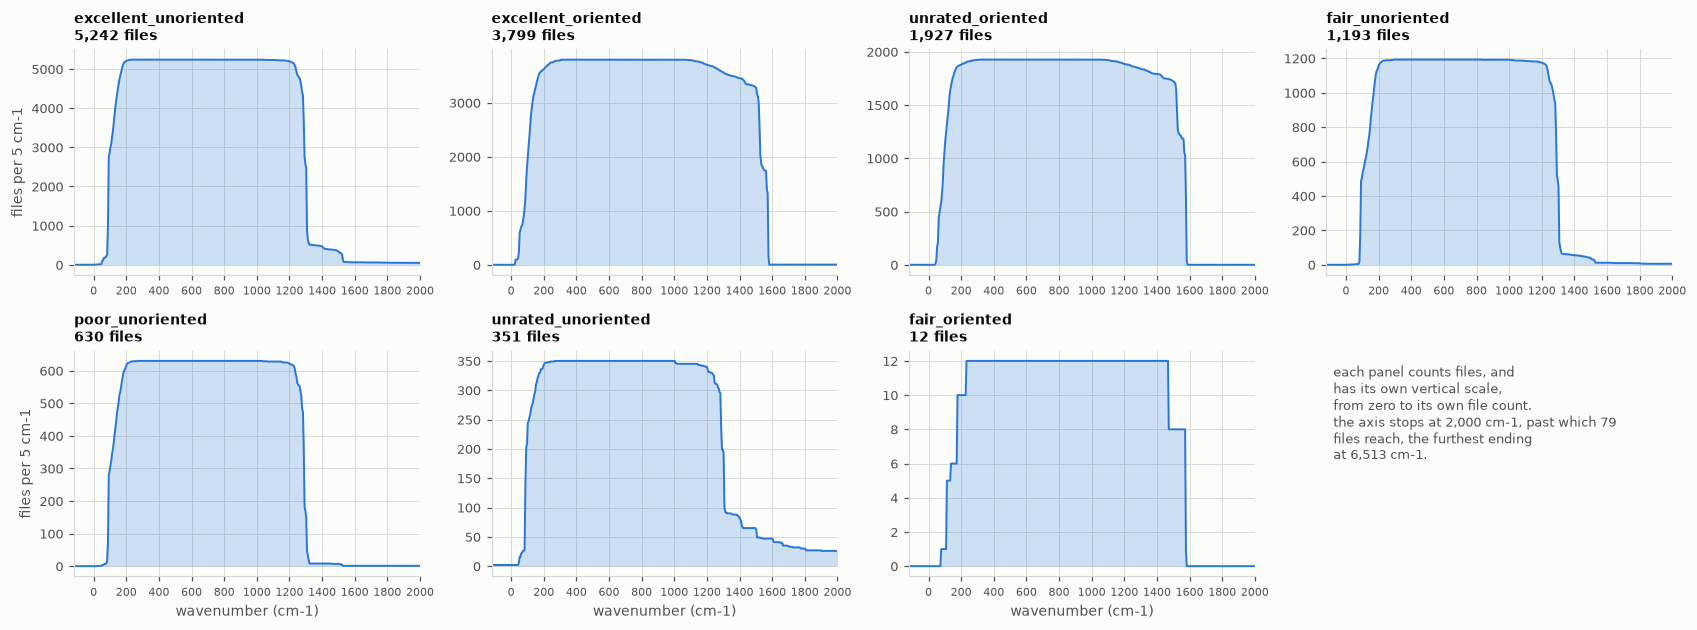

In [9]:
# How many of each archive's files hold data at each wavenumber. A file counts at every bin
# between its own ends, so a file spanning 200 cm-1 counts in forty of the 5 cm-1 bins.
step = 5.0
lo = np.floor(kept.x_min.min() / step) * step
hi = np.ceil(kept.x_max.max() / step) * step
edges = np.arange(lo, hi + step, step)
centres = (edges[:-1] + edges[1:]) / 2

bins = {}
for name, part in kept.groupby("archive"):
    first = np.clip(np.searchsorted(edges, part.x_min.values, side="right") - 1,
                    0, centres.size - 1)
    last = np.clip(np.searchsorted(edges, part.x_max.values, side="right") - 1,
                   0, centres.size - 1)
    # A difference array turns "add one to every bin this file spans" into two writes.
    change = np.zeros(centres.size + 1)
    np.add.at(change, first, 1)
    np.add.at(change, last + 1, -1)
    bins[name] = np.cumsum(change)[:centres.size]

order = kept.groupby("archive").size().sort_values(ascending=False).index
rows = []
for name in order:
    counts = bins[name]
    files = int((kept.archive == name).sum())
    half = counts >= files / 2
    rows.append({
        "files": files,
        "fullest bin": centres[counts.argmax()],
        "files there": int(counts.max()),
        "half or more from": centres[half].min() if half.any() else np.nan,
        "half or more to": centres[half].max() if half.any() else np.nan,
    })
print("how many of each archive's files hold each wavenumber:")
print(pd.DataFrame(rows, index=order).round(1).to_string())
print()
pooled = np.sum(list(bins.values()), axis=0)
print(f"over the seven archives together, the widest overlap is at "
      f"{centres[pooled.argmax()]:,.0f} cm-1, where {int(pooled.max()):,} files hold data")

# The axis stops at 2000 cm-1, which every file but a handful reaches, so that labels every
# 200 cm-1 stay legible in a panel this wide. The files reaching past it are counted instead.
cap = 2000.0
print(f"the axis stops at {cap:,.0f} cm-1; {int((kept.x_max > cap).sum()):,} files reach past "
      f"it, the furthest of them ending at {kept.x_max.max():,.0f} cm-1")

fig, axes = plt.subplots(2, 4, figsize=(15.5, 5.8))
for ax, name in zip(axes.ravel(), order):
    ax.fill_between(centres, bins[name], color=BLUE, alpha=0.22, linewidth=0)
    ax.plot(centres, bins[name], color=BLUE, lw=1.3)
    ax.set_title(f"{name}\n{int((kept.archive == name).sum()):,} files", fontsize=9, loc="left")
    ax.set_xlim(edges[0], cap)
    # Both rows carry the labels, and they run every 200 cm-1 rather than at round thousands.
    ax.set_xticks(np.arange(0, cap + 1, 200))
    ax.tick_params(axis="x", labelsize=7.5)
note = axes.ravel()[len(order)]
note.axis("off")
note.text(0.02, 0.94, f"each panel counts files, and\nhas its own vertical scale,\nfrom zero"
                      f" to its own file count.\nthe axis stops at {cap:,.0f} cm-1, past which "
                      f"{int((kept.x_max > cap).sum()):,}\nfiles reach, the furthest ending\n"
                      f"at {kept.x_max.max():,.0f} cm-1.",
          ha="left", va="top", fontsize=8.5, color=INK_SOFT)
for ax in axes[-1]:
    ax.set_xlabel("wavenumber (cm-1)")
for ax in axes[:, 0]:
    ax.set_ylabel("files per 5 cm-1")
plt.tight_layout()
plt.show()


## 7. The window that keeps the most files

Section 5 counts, for each candidate window, the files whose own range covers it. A file holds
one spectrum, so that count is the number of spectra the window would keep, and it is what this
section maximises.

The window that keeps the most files is the narrowest one the grid allows, since the less
wavenumber a window covers the easier it is for a spectrum to contain it. The useful question is
therefore the widest window that still keeps a given share of the files, and the table below
answers it at several shares.

The points those files would contribute are reported beside it, because the two pull apart. A
narrow window keeps the most files but takes few points from each, and a file on a coarse grid
brings fewer points to the same window than one on a fine grid. The windows are scored on the
grid of starts and ends that section 5 uses, at a resolution of 25 cm-1.


In [10]:
# A shared window has to sit inside every spectrum it keeps, and each kept file is one
# spectrum, so a window is scored on the files it keeps: the kept files whose own range
# contains it. The points those files would contribute follow from their own spacing, which
# is uniform within most files, and are reported beside the file count.
w_min = kept.x_min.values
w_max = kept.x_max.values
w_spacing = kept.spacing.values
w_class = pd.factorize(kept.mineral)[0]

lows = np.arange(-150.0, 1851.0, 25.0)
highs = np.arange(250.0, 2651.0, 25.0)
files = np.zeros((lows.size, highs.size), dtype=np.int32)
minerals = np.zeros_like(files)
testable = np.zeros_like(files)
points = np.zeros((lows.size, highs.size), dtype=np.int64)

for i, low in enumerate(lows):
    below = w_min <= low
    if not below.any():
        continue
    for j, high in enumerate(highs):
        if high - low < 25:
            continue
        inside = below & (w_max >= high)
        count = int(inside.sum())
        if count == 0:
            continue
        files[i, j] = count
        points[i, j] = int(np.sum(np.round((high - low) / w_spacing[inside]) + 1))
        per_class = np.bincount(w_class[inside])
        minerals[i, j] = int((per_class > 0).sum())
        testable[i, j] = int((per_class >= 2).sum())


def line(i, j, tag):
    """One row of the summary: where a window sits, the files it keeps, and what they hold."""
    low, high = lows[i], highs[j]
    print(f"  {tag:24s} {low:7.0f} to {high:6.0f} cm-1 ({high - low:5.0f} wide): "
          f"{files[i, j]:6,d} files, {files[i, j] / len(kept) * 100:6.2f}% of the set, "
          f"{minerals[i, j]:5,d} minerals, {testable[i, j]:5,d} testable, "
          f"{points[i, j] / 1e6:5.1f}M points, {points[i, j] / files[i, j]:5.0f} a file")


print(f"kept files {len(kept):,}")
print(f"minerals holding two spectra or more, which a leave-one-out split can test: "
      f"{int((kept.groupby('mineral').size() >= 2).sum()):,}")
print()
best = np.unravel_index(files.argmax(), files.shape)
print("the window that keeps the most files:")
line(*best, "most files anywhere")
print()
print("the widest window that still keeps a given share of the kept files:")
for share in (0.99, 0.95, 0.90, 0.80, 0.50):
    allowed = files >= share * len(kept)
    masked = np.where(allowed, highs[None, :] - lows[:, None], -1)
    line(*np.unravel_index(masked.argmax(), masked.shape), f"{share:.0%} of the files")
print()
print("for comparison, the window that holds the most points:")
line(*np.unravel_index(points.argmax(), points.shape), "most points anywhere")


kept files 13,154
minerals holding two spectra or more, which a leave-one-out split can test: 1,912

the window that keeps the most files:
  most files anywhere          400 to    425 cm-1 (   25 wide): 13,152 files,  99.98% of the set, 2,114 minerals, 1,912 testable,   0.5M points,    38 a file

the widest window that still keeps a given share of the kept files:
  99% of the files             250 to   1100 cm-1 (  850 wide): 13,032 files,  99.07% of the set, 2,106 minerals, 1,906 testable,  16.3M points,  1250 a file
  95% of the files             200 to   1200 cm-1 ( 1000 wide): 12,576 files,  95.61% of the set, 2,089 minerals, 1,855 testable,  18.6M points,  1479 a file
  90% of the files             175 to   1225 cm-1 ( 1050 wide): 11,981 files,  91.08% of the set, 2,032 minerals, 1,718 testable,  18.4M points,  1538 a file
  80% of the files             175 to   1275 cm-1 ( 1100 wide): 10,932 files,  83.11% of the set, 1,975 minerals, 1,463 testable,  17.1M points,  1562 a file
  

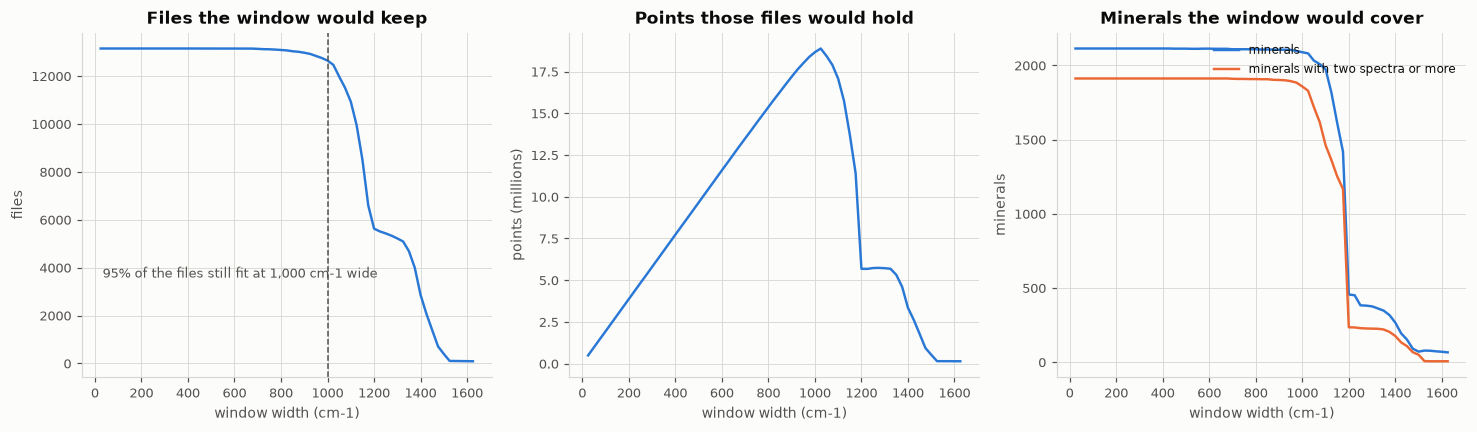

In [11]:
# What a wider window costs, at the best position for each width, where best means keeping
# the most files.
widths = np.arange(25, 1626, 25)
peak = []
for width in widths:
    masked = np.where((highs[None, :] - lows[:, None]) >= width, files, -1)
    i, j = np.unravel_index(masked.argmax(), masked.shape)
    peak.append((files[i, j], points[i, j] / 1e6, minerals[i, j], testable[i, j]))
peak = np.asarray(peak)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
axes[0].plot(widths, peak[:, 0], color=BLUE, lw=1.6)
axes[0].set_title("Files the window would keep")
axes[0].set_ylabel("files")

axes[1].plot(widths, peak[:, 1], color=BLUE, lw=1.6)
axes[1].set_title("Points those files would hold")
axes[1].set_ylabel("points (millions)")

all_minerals, = axes[2].plot(widths, peak[:, 2], color=BLUE, lw=1.6, label="minerals")
testable, = axes[2].plot(widths, peak[:, 3], color=ORANGE, lw=1.6,
                         label="minerals with two spectra or more")
axes[2].set_title("Minerals the window would cover")
axes[2].set_ylabel("minerals")
axes[2].legend(handles=[all_minerals, testable], loc="upper right", fontsize=8)

for ax in axes:
    ax.set_xlabel("window width (cm-1)")

# The files a window can keep fall away as it widens. The mark is the widest window that still
# keeps 95% of them, which is about as wide as a shared window can sensibly go.
w95 = int(widths[peak[:, 0] >= 0.95 * len(kept)].max())
axes[0].axvline(w95, color=INK_SOFT, lw=1, ls="--")
axes[0].annotate(f"95% of the files still fit at {w95:,d} cm-1 wide",
                 xy=(w95, 0.95 * len(kept)), xycoords="data",
                 xytext=(0.05, 0.30), textcoords="axes fraction",
                 ha="left", va="center", fontsize=8.5, color=INK_SOFT)
plt.tight_layout()
plt.show()


## 8. Windows fixed by hand, and the trimming they cost

Section 7 lets the search choose the window and truncates every spectrum that is wider than it.
This section fixes windows by hand and counts the files that suit each of them as they stand.

Each window is written as its start and its end, then how far past each end a file may run and
still count. A file's own start has to fall in the band below the window's start and its own end
in the band above the window's end, and both have to hold: the allowance is spent at each end on
its own, not once between the two. A file that stops short of the window at either end is never
counted, since the wavenumbers it is missing are not in the file to be used, and one that runs
past a band is left out too, which is only a matter of how much truncation is allowed before the
file stops matching the window's own shape.

Two windows are set at the top of the cell. The first is 200 to 1600 cm-1 with 50 cm-1 allowed
at each end. The second is 100 to 1250 cm-1 with the start left open, so a file may open any
distance below 100 cm-1, and the end allowed to run up to 1350 cm-1. A margin of `None` is what
leaves an end open. Beside each window the band above its end is widened in steps, so the cost of
a tighter or a looser end can be read off the table. The same rule is then asked of every window
on section 7's grid at 50 cm-1 at each end, which does not depend on the windows fixed here.


200 to 1600 cm-1: 121 of the 13,154 kept files cover it (0.92%)
  a file counts when its start falls in 150 to 200 cm-1 and its end falls in 1600 to 1650 cm-1:
        0 files ( 0.00%),     0 minerals,     0 testable,   0.0M points
  the same, widening the band above the window's end:
    end in 1600 to 1625 cm-1                0 files ( 0.00%),     0 minerals,     0 testable,   0.0M points
    end in 1600 to 1650 cm-1                0 files ( 0.00%),     0 minerals,     0 testable,   0.0M points
    end in 1600 to 1700 cm-1                4 files ( 0.03%),     4 minerals,     0 testable,   0.0M points
    end in 1600 to 1800 cm-1                5 files ( 0.04%),     5 minerals,     0 testable,   0.0M points
    end in 1600 to 2000 cm-1                7 files ( 0.05%),     6 minerals,     1 testable,   0.0M points
    end in 1600 to 2400 cm-1                9 files ( 0.07%),     8 minerals,     1 testable,   0.0M points
  how far the covering files run past each end:
    at the start  

over every window on the grid, with 50 cm-1 allowed at each end:
  the most files any window keeps      125 to  1275 cm-1 (1150 wide): 3,989 files (30.33% of the kept set)

the best window of each width, counted both ways: the files that suit it as they
stand at this allowance, and the files that cover it however far they run past it:
    200 cm-1 wide      0 to   200 cm-1:     0 as they stand ( 0.00%),      6 with truncation ( 0.05%)
    400 cm-1 wide      0 to   400 cm-1:     0 as they stand ( 0.00%),      6 with truncation ( 0.05%)
    600 cm-1 wide    200 to   800 cm-1:     1 as they stand ( 0.01%), 12,809 with truncation (97.38%)
    800 cm-1 wide    150 to   950 cm-1:     6 as they stand ( 0.05%), 11,070 with truncation (84.16%)
  1,000 cm-1 wide    200 to  1200 cm-1:   200 as they stand ( 1.52%), 12,576 with truncation (95.61%)
  1,200 cm-1 wide    100 to  1300 cm-1: 1,671 as they stand (12.70%),  4,834 with truncation (36.75%)


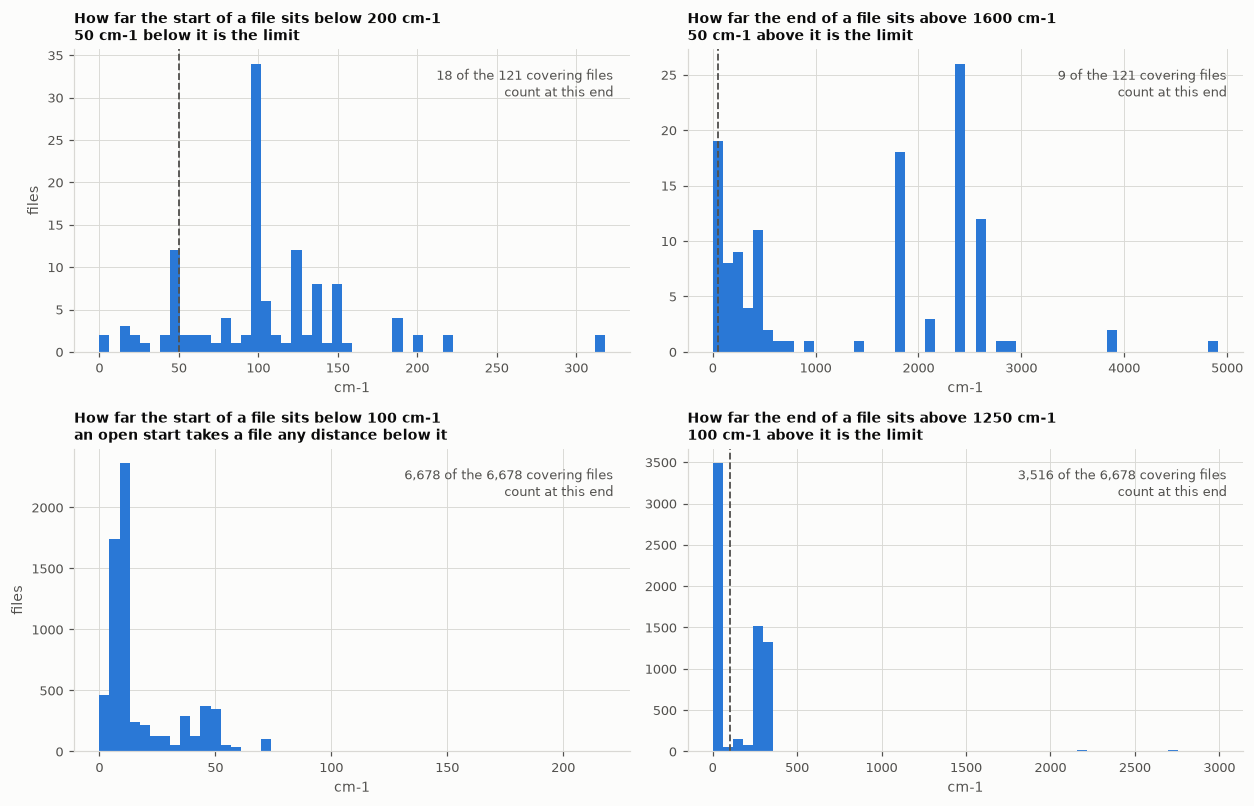

In [12]:
# Each entry is a window, its start and end in cm-1, then how far past each end a file may run.
# A file counts when its own start falls in the band below the window's start and its own end in
# the band above the window's end, both of which have to hold. A None leaves that end open, so a
# file may run past it any distance. Change these numbers to try another window.
windows = [
    (200.0, 1600.0, 50.0, 50.0),
    (100.0, 1250.0, None, 100.0),
]
end_sweep = (25, 50, 100, 200, 400, 800)
grid_past = 50.0

x_lo = kept.x_min.values
x_hi = kept.x_max.values
spacing = kept.spacing.values
classes = pd.factorize(kept.mineral)[0]
archive_ids, archive_names = pd.factorize(kept.archive)


def keeps_for(low, high, start_past, end_past):
    """The files a window keeps: those covering it with each end inside its own band.

    Args:
        low, high (float): the window, in cm-1.
        start_past (float or None): how far below the window's start a file may open, or None
            to leave that end open.
        end_past (float or None): how far above the window's end a file may finish, or None to
            leave that end open.

    Returns:
        np.ndarray: a mask over the kept files.
    """
    keeps = (x_lo <= low) & (x_hi >= high)
    if start_past is not None:
        keeps &= x_lo >= low - start_past
    if end_past is not None:
        keeps &= x_hi <= high + end_past
    return keeps


def band(edge, past, below):
    """One end's band, written out for printing.

    Args:
        edge (float): the window's own start or end, in cm-1.
        past (float or None): how far past `edge` a file may run, or None for any distance.
        below (bool): True for the band below a window's start, False for the one above its end.

    Returns:
        str: the band in words, with the preposition that introduces it.
    """
    if past is None:
        return f"anywhere at or {'below' if below else 'above'} {edge:.0f} cm-1"
    return (f"in {edge - past:.0f} to {edge:.0f} cm-1" if below
            else f"in {edge:.0f} to {edge + past:.0f} cm-1")


def hold(keeps, low, high):
    """The points the kept files would contribute inside the window, from their own spacing."""
    return int(np.sum(np.round((high - low) / spacing[keeps]) + 1))


for low, high, start_past, end_past in windows:
    covers = (x_lo <= low) & (x_hi >= high)
    keeps = keeps_for(low, high, start_past, end_past)
    found = np.bincount(classes[keeps], minlength=classes.max() + 1)
    split = np.bincount(archive_ids[keeps], minlength=archive_names.size)
    print(f"{low:.0f} to {high:.0f} cm-1: {int(covers.sum()):,} of the {len(kept):,} kept files "
          f"cover it ({covers.sum() / len(kept) * 100:.2f}%)")
    print(f"  a file counts when its start falls {band(low, start_past, True)} and its end "
          f"falls {band(high, end_past, False)}:")
    print(f"    {int(keeps.sum()):5,d} files ({keeps.sum() / len(kept) * 100:5.2f}%), "
          f"{int((found > 0).sum()):5,d} minerals, {int((found >= 2).sum()):5,d} testable, "
          f"{hold(keeps, low, high) / 1e6:5.1f}M points")
    if keeps.any():
        print("    by archive: " + ", ".join(f"{name} {int(n):,}"
                                             for name, n in zip(archive_names, split) if n))
    print("  the same, widening the band above the window's end:")
    for past in end_sweep:
        wider = keeps_for(low, high, start_past, past)
        found = np.bincount(classes[wider], minlength=classes.max() + 1)
        print(f"    end {band(high, past, False):31s} {int(wider.sum()):5,d} files "
              f"({wider.sum() / len(kept) * 100:5.2f}%), {int((found > 0).sum()):5,d} minerals, "
              f"{int((found >= 2).sum()):5,d} testable, {hold(wider, low, high) / 1e6:5.1f}M "
              f"points")
    print("  how far the covering files run past each end:")
    for name, values in [("at the start", low - x_lo[covers]),
                         ("at the end", x_hi[covers] - high)]:
        tenth, median, ninetieth = np.percentile(values, [10, 50, 90])
        print(f"    {name:13s} a tenth under {tenth:6.0f} cm-1, median {median:6.0f}, "
              f"a tenth over {ninetieth:6.0f}")
    print()

# The same rule asked of every window on the 25 cm-1 grid section 7 uses, at grid_past cm-1
# allowed at each end. A file matches a window when the window's start falls between the file's
# own start and that start plus the allowance, and its end falls between the file's own end minus
# the allowance and that end, so the count over the grid is one product of the two per-file
# masks.
gl = np.arange(0.0, 1801.0, 25.0)
gh = np.arange(200.0, 2601.0, 25.0)
starts = (gl[None, :] >= x_lo[:, None]) & (gl[None, :] <= x_lo[:, None] + grid_past)
ends = (gh[None, :] >= x_hi[:, None] - grid_past) & (gh[None, :] <= x_hi[:, None])
width = gh[None, :] - gl[:, None]
near = np.where(width >= 25, starts.astype(np.int32).T @ ends.astype(np.int32), 0)

# The grid should agree with the first window counted above, which is the cheapest check that
# the product of the two masks counts the files it claims to.
first_low, first_high, first_start, first_end = windows[0]
assert first_start == grid_past and first_end == grid_past
assert near[int((first_low - gl[0]) / 25), int((first_high - gh[0]) / 25)] == \
    int(keeps_for(first_low, first_high, grid_past, grid_past).sum())

# What section 7's own rule, a file that covers the window, would keep in the same windows.
hold_any = (gl[None, :] >= x_lo[:, None]).astype(np.int32).T @ \
           (gh[None, :] <= x_hi[:, None]).astype(np.int32)

print(f"over every window on the grid, with {grid_past:.0f} cm-1 allowed at each end:")
i, j = np.unravel_index(near.argmax(), near.shape)
print(f"  the most files any window keeps    {gl[i]:5.0f} to {gh[j]:5.0f} cm-1 "
      f"({width[i, j]:4.0f} wide): {near[i, j]:5,d} files "
      f"({near[i, j] / len(kept) * 100:.2f}% of the kept set)")
print()
print("the best window of each width, counted both ways: the files that suit it as they")
print("stand at this allowance, and the files that cover it however far they run past it:")
for wanted in (200, 400, 600, 800, 1000, 1200):
    exact = (width >= wanted) & (width < wanted + 25)
    i, j = np.unravel_index(np.where(exact, near, -1).argmax(), width.shape)
    print(f"  {wanted:5,d} cm-1 wide  {gl[i]:5.0f} to {gh[j]:5.0f} cm-1: {near[i, j]:5,d} as "
          f"they stand ({near[i, j] / len(kept) * 100:5.2f}%), {hold_any[i, j]:6,d} with "
          f"truncation ({hold_any[i, j] / len(kept) * 100:5.2f}%)")

# One row per window: how far past each end of it the covering files run, with that end's band
# marked where the window sets one.
fig, axes = plt.subplots(len(windows), 2, figsize=(11.5, 3.7 * len(windows)), squeeze=False)
for row, (low, high, start_past, end_past) in enumerate(windows):
    covers = (x_lo <= low) & (x_hi >= high)
    panels = [
        (low - x_lo[covers], start_past,
         f"How far the start of a file sits below {low:.0f} cm-1",
         "an open start takes a file any distance below it" if start_past is None
         else f"{start_past:.0f} cm-1 below it is the limit"),
        (x_hi[covers] - high, end_past,
         f"How far the end of a file sits above {high:.0f} cm-1",
         f"{end_past:.0f} cm-1 above it is the limit"),
    ]
    for ax, (values, past, title, subtitle) in zip(axes[row], panels):
        ax.hist(values, bins=50, color=BLUE)
        if past is not None:
            ax.axvline(past, color=INK_SOFT, lw=1.2, ls="--")
        counted = values.size if past is None else int((values <= past).sum())
        ax.annotate(f"{counted:,} of the {values.size:,} covering files\ncount at this end",
                    xy=(0.97, 0.94), xycoords="axes fraction", ha="right", va="top", fontsize=8.5,
                    color=INK_SOFT)
        ax.set_title(f"{title}\n{subtitle}", fontsize=9, loc="left")
        ax.set_xlabel("cm-1")
    axes[row, 0].set_ylabel("files")
plt.tight_layout()
plt.show()


## 9. Resolution

The spacing is `(x_max - x_min) / (points - 1)` for each file, which is exact when the grid
is uniform and an average when it is not. Section 15 checks that assumption against the
actual wavenumber differences on a sample.

In [13]:
resolution = kept.groupby("archive")["spacing"].describe(percentiles=[0.05, 0.5, 0.95]).round(4)
print(f"spacing over the kept set: min {kept.spacing.min():.4f}, "
      f"median {kept.spacing.median():.4f}, max {kept.spacing.max():.4f} cm-1")
print()
resolution

spacing over the kept set: min 0.1851, median 0.4821, max 3.8823 cm-1



,count,mean,std,min,5%,50%,95%,max
archive,,,,,,,,
excellent_oriented,3799.0,1.2059,0.0783,0.5003,1.1267,1.1650,1.2935,1.3271
excellent_unoriented,5242.0,0.5709,0.2857,0.1851,0.4821,0.4821,1.2820,3.7512
fair_oriented,12.0,1.1304,0.0065,1.1228,1.1230,1.1275,1.1386,1.1386
fair_unoriented,1193.0,0.5386,0.2424,0.3057,0.4821,0.4821,1.2765,3.8823
poor_unoriented,630.0,0.4951,0.1070,0.4821,0.4821,0.4821,0.4821,1.9285
unrated_oriented,1927.0,1.1822,0.0773,0.4821,1.1272,1.1324,1.2897,1.3143
unrated_unoriented,351.0,0.8240,0.6553,0.3101,0.4821,0.4821,2.5144,3.4221


In [14]:
print("most common spacings, rounded to 0.05 cm-1:")
rounded = (kept.spacing.round(2) * 20).round() / 20
for value, count in rounded.value_counts().head(12).items():
    print(f"  {value:6.2f} cm-1  {int(count):7,d} files")
print()
print("spacing by excitation wavelength:")
print(kept.groupby("wavelength_nm")["spacing"]
      .agg(files="size", minimum="min", median="median", maximum="max")
      .round(4).to_string())

most common spacings, rounded to 0.05 cm-1:
    0.50 cm-1    6,695 files
    1.15 cm-1    3,028 files
    1.30 cm-1    2,730 files
    1.25 cm-1      267 files
    1.10 cm-1      164 files
    1.70 cm-1       61 files
    1.95 cm-1       35 files
    1.00 cm-1       18 files
    1.65 cm-1       12 files
    0.95 cm-1       12 files
    0.80 cm-1       10 files
    2.50 cm-1        9 files

spacing by excitation wavelength:
               files  minimum  median  maximum
wavelength_nm                                 
458.0              1   1.3903  1.3903   1.3903
488.0              2   0.5685  1.9138   3.2591
514.0           6225   0.5000  1.1520   2.5301
514.5             10   0.5003  0.5495   1.3874
515.0              2   1.8294  1.8296   1.8298
523.0              1   1.6333  1.6333   1.6333
532.0           3514   0.1851  0.4821   3.8823
532.6              2   1.4897  1.4897   1.4897
632.0             12   0.9457  1.0933   1.6608
632.8              1   0.7740  0.7740   0.7740
633.0    

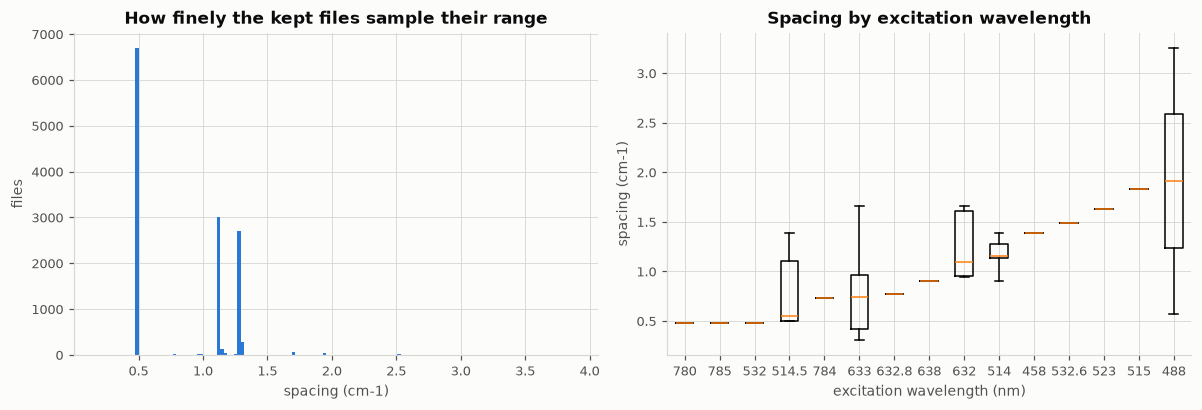

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(kept.spacing.dropna().clip(0, 6), bins=140, color=BLUE)
axes[0].set_xlabel("spacing (cm-1)")
axes[0].set_ylabel("files")
axes[0].set_title("How finely the kept files sample their range")

order = kept.groupby("wavelength_nm")["spacing"].median().sort_values().index
data = [kept.loc[kept.wavelength_nm == w, "spacing"].dropna().values for w in order]
axes[1].boxplot(data, tick_labels=[f"{w:g}" for w in order], showfliers=False)
axes[1].set_xlabel("excitation wavelength (nm)")
axes[1].set_ylabel("spacing (cm-1)")
axes[1].set_title("Spacing by excitation wavelength")
plt.tight_layout()
plt.show()

## 10. How many points a spectrum has

This is the length of the model's input. Each export sits on its own grid, so the count
varies between files.

In [16]:
point_counts = kept.groupby("archive")["points"].describe(percentiles=[0.05, 0.5, 0.95]).round(1)
print(f"points per spectrum: min {kept.points.min():,.0f}, "
      f"median {kept.points.median():,.0f}, max {kept.points.max():,.0f}")
print()
point_counts

points per spectrum: min 351, median 2,201, max 10,798



,count,mean,std,min,5%,50%,95%,max
archive,,,,,,,,
excellent_oriented,3799.0,1179.0,229.0,619.0,912.0,1150.0,1340.0,7966.0
excellent_unoriented,5242.0,2313.6,443.4,442.0,1104.0,2456.0,2516.0,7965.0
fair_oriented,12.0,1226.0,42.7,1192.0,1192.0,1216.5,1298.8,1329.0
fair_unoriented,1193.0,2326.7,452.5,397.0,1102.2,2405.0,2516.0,10798.0
poor_unoriented,630.0,2387.5,184.5,837.0,2197.4,2438.0,2516.0,2539.0
unrated_oriented,1927.0,1218.8,136.4,703.0,958.3,1279.0,1340.0,2359.0
unrated_unoriented,351.0,2166.8,886.5,351.0,617.5,2477.0,2833.0,10747.0


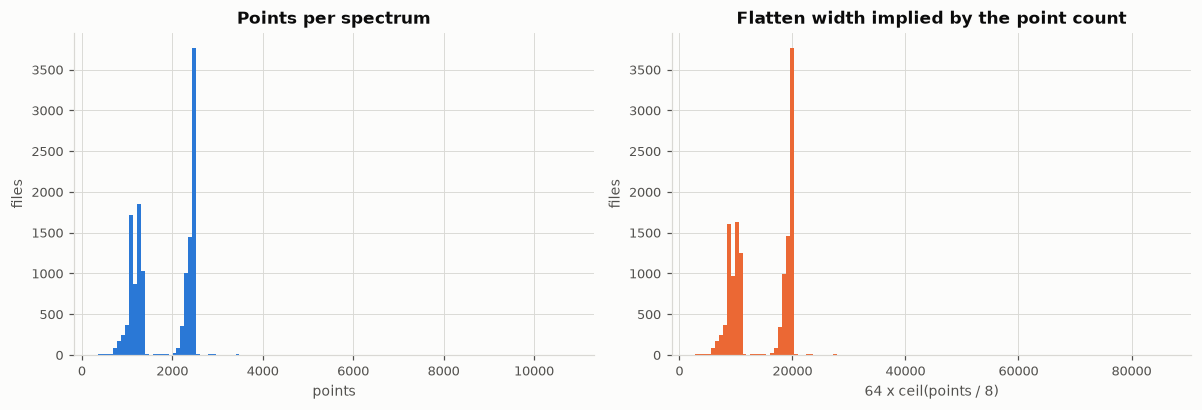

,count,mean,std,min,50%,max
archive,,,,,,
excellent_oriented,3799.0,9459.0,1832.0,4992.0,9216.0,63744.0
excellent_unoriented,5242.0,18536.0,3547.0,3584.0,19648.0,63744.0
fair_oriented,12.0,9829.0,355.0,9536.0,9760.0,10688.0
fair_unoriented,1193.0,18640.0,3619.0,3200.0,19264.0,86400.0
poor_unoriented,630.0,19126.0,1475.0,6720.0,19520.0,20352.0
unrated_oriented,1927.0,9779.0,1091.0,5632.0,10240.0,18880.0
unrated_unoriented,351.0,17360.0,7093.0,2816.0,19840.0,86016.0


In [17]:
# The width the dense head would receive if the three 2x2 pooling steps halve the axis
# three times and the last block's 64 maps are flattened. Arithmetic on the point count,
# not a claim about the model.
kept["flatten_width"] = 64 * np.ceil(kept.points / 8)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(kept.points, bins=120, color=BLUE)
axes[0].set_xlabel("points")
axes[0].set_ylabel("files")
axes[0].set_title("Points per spectrum")
axes[1].hist(kept.flatten_width, bins=120, color=ORANGE)
axes[1].set_xlabel("64 x ceil(points / 8)")
axes[1].set_ylabel("files")
axes[1].set_title("Flatten width implied by the point count")
plt.tight_layout()
plt.show()

kept.groupby("archive")["flatten_width"].describe(percentiles=[0.5]).round(0)

## 11. The classes

A class here is a mineral species, taken from the `NAMES` field.

In [18]:
per_mineral = kept.groupby("mineral").size().sort_values(ascending=False)

print(f"minerals in the kept set:            {len(per_mineral):,}")
print(f"spectra in the kept set:             {int(per_mineral.sum()):,}")
print(f"minerals with a single spectrum:     {int((per_mineral == 1).sum()):,}")
print(f"minerals with two or more:           {int((per_mineral >= 2).sum()):,}")
print(f"minerals with five or more:          {int((per_mineral >= 5).sum()):,}")
print(f"median spectra per mineral:          {per_mineral.median():.0f}")
print(f"spectra in the ten largest classes:  {per_mineral.head(10).sum():,} "
      f"({per_mineral.head(10).sum() / per_mineral.sum() * 100:.1f}% of the kept set)")
print(f"minerals named anywhere in the pool: {pool.mineral.nunique():,}")
print()
per_mineral.head(20).rename("spectra").to_frame()

minerals in the kept set:            2,116
spectra in the kept set:             13,154
minerals with a single spectrum:     204
minerals with two or more:           1,912
minerals with five or more:          427
median spectra per mineral:          2
spectra in the ten largest classes:  1,284 (9.8% of the kept set)
minerals named anywhere in the pool: 2,509



,spectra
mineral,
Diopside,190
Axinite-(Fe),157
Fluorapatite,139
Epidote,125
Beryl,123
Albite,115
Microcline,112
Forsterite,110
Enstatite,107


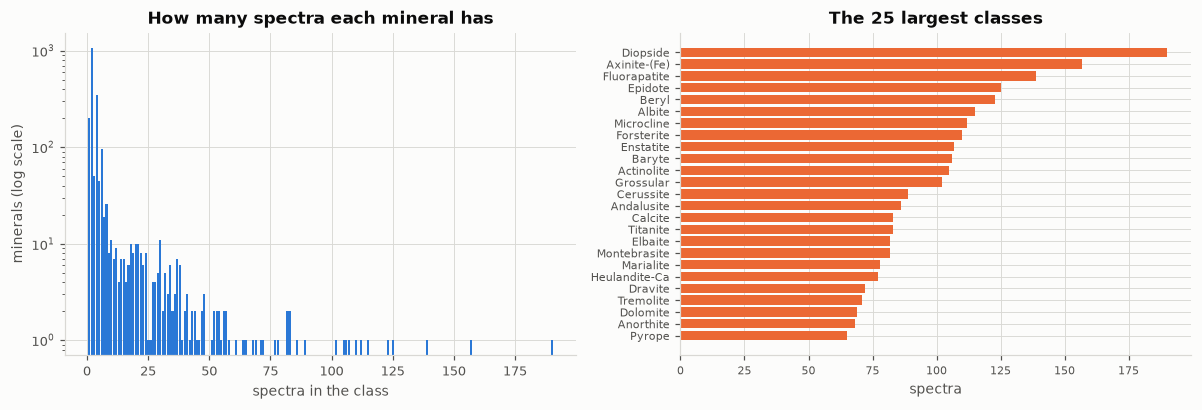

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
hist = per_mineral.value_counts().sort_index()
axes[0].bar(hist.index, hist.values, color=BLUE, width=0.85)
axes[0].set_yscale("log")
axes[0].set_xlabel("spectra in the class")
axes[0].set_ylabel("minerals (log scale)")
axes[0].set_title("How many spectra each mineral has")

top = per_mineral.head(25)[::-1]
axes[1].barh(top.index, top.values, color=ORANGE)
axes[1].set_xlabel("spectra")
axes[1].set_title("The 25 largest classes")
axes[1].tick_params(labelsize=7.5)
plt.tight_layout()
plt.show()

## 12. Excitation wavelength

Taken from the `RAMAN WAVELENGTH` field of each file, not from the file name.

In [20]:
print("kept files by excitation wavelength:")
for value, count in kept.wavelength_nm.value_counts(dropna=False).sort_index().items():
    label = "no number in RAMAN WAVELENGTH" if pd.isna(value) else f"{value:g} nm"
    print(f"  {int(count):7,d}  {label}")
print()
cross = pd.crosstab(kept.archive, kept.wavelength_nm, dropna=False)
# A column label of NaN cannot be reached by a dict lookup, so it is renamed by position.
cross.columns = ["unknown" if pd.isna(column) else column for column in cross.columns]
cross["files"] = cross.sum(axis=1)
cross

kept files by excitation wavelength:
        1  458 nm
        2  488 nm
    6,225  514 nm
       10  514.5 nm
        2  515 nm
        1  523 nm
    3,514  532 nm
        2  532.6 nm
       12  632 nm
        1  632.8 nm
       12  633 nm
        1  638 nm
    2,384  780 nm
        1  784 nm
      981  785 nm
        5  no number in RAMAN WAVELENGTH



,458.0,488.0,514.0,514.5,515.0,523.0,532.0,532.6,632.0,632.8,633.0,638.0,780.0,784.0,785.0,unknown,files
archive,,,,,,,,,,,,,,,,,
excellent_oriented,0,0,3793,3,0,0,0,0,0,0,0,0,0,0,3,0,3799
excellent_unoriented,1,0,389,6,0,0,2616,0,0,1,4,0,1584,0,639,2,5242
fair_oriented,0,0,12,0,0,0,0,0,0,0,0,0,0,0,0,0,12
fair_unoriented,0,0,66,1,0,0,534,2,1,0,1,1,406,0,178,3,1193
poor_unoriented,0,0,9,0,0,0,209,0,0,0,0,0,298,0,114,0,630
unrated_oriented,0,0,1919,0,0,0,4,0,2,0,0,0,0,0,2,0,1927
unrated_unoriented,0,2,37,0,2,1,151,0,9,0,7,0,96,1,45,0,351


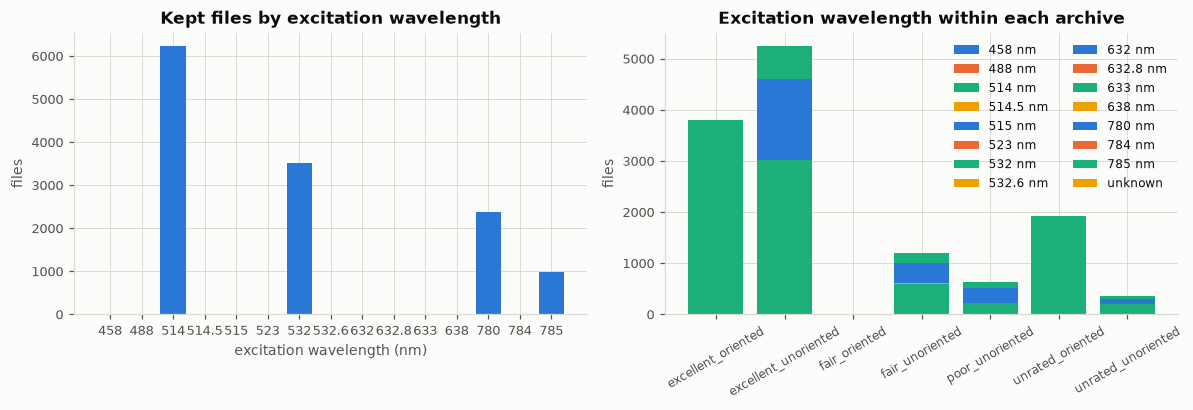

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts = kept.wavelength_nm.value_counts().sort_index()
axes[0].bar([f"{w:g}" for w in counts.index], counts.values, color=BLUE)
axes[0].set_xlabel("excitation wavelength (nm)")
axes[0].set_ylabel("files")
axes[0].set_title("Kept files by excitation wavelength")

# dropna=False so the files with no number in RAMAN WAVELENGTH keep a column of their own
# instead of disappearing from the totals.
grid = pd.crosstab(kept.archive, kept.wavelength_nm, dropna=False)
labels = ["unknown" if pd.isna(column) else f"{column:g} nm" for column in grid.columns]
bottom = np.zeros(len(grid))
for index, column in enumerate(grid.columns):
    colour = [BLUE, ORANGE, AQUA, YELLOW][index % 4]
    axes[1].bar(grid.index, grid[column].values, bottom=bottom,
                label=labels[index], color=colour)
    bottom += grid[column].values
axes[1].set_ylabel("files")
axes[1].set_title("Excitation wavelength within each archive")
axes[1].tick_params(axis="x", rotation=30, labelsize=8)
axes[1].legend(fontsize=8, ncols=2)
plt.tight_layout()
plt.show()

## 13. Duplication between the RAW and Processed exports

One measurement is exported up to twice, once raw and once processed. The `measurement` key
is the file name without the export kind and the hash, so it groups those two exports
together.

In [22]:
kinds = pool.groupby("measurement")["kind"].agg(lambda s: tuple(sorted(set(s))))

print("exports per measurement, over the whole pool:")
for value, count in kinds.value_counts().items():
    print(f"  {int(count):7,d} measurements with {value}")
print()
print(f"measurements with both a RAW and a Processed export: "
      f"{int((kinds == ('Processed', 'RAW')).sum()):,}")
print(f"measurements in the kept set: {kept.measurement.nunique():,}")
print(f"kept files per kept measurement, most common: "
      f"{kept.groupby('measurement').size().value_counts().head(4).to_dict()}")

kept_measurements = set(kept.measurement)
twins = pool[(pool.kind == "Processed") & pool.measurement.isin(kept_measurements)]
print(f"kept RAW files whose Processed twin is also in the pool: {len(twins):,} "
      f"({len(twins) / len(kept) * 100:.1f}% of the kept set)")

exports per measurement, over the whole pool:
   13,867 measurements with ('Processed', 'RAW')
      219 measurements with ('RAW',)
      125 measurements with ('Processed',)

measurements with both a RAW and a Processed export: 13,867
measurements in the kept set: 13,137
kept files per kept measurement, most common: {1: 13120, 2: 17}
kept RAW files whose Processed twin is also in the pool: 12,969 (98.6% of the kept set)


## 14. Coverage across archives

Which archives contribute which minerals, and how many minerals more than one archive
holds.

In [23]:
per_archive_minerals = kept.groupby("archive")["mineral"].nunique()
archives_per_mineral = kept.groupby("mineral")["archive"].nunique()

print("files, measurements and minerals per archive:")
print(pd.DataFrame({
    "files": kept.groupby("archive").size(),
    "measurements": kept.groupby("archive")["measurement"].nunique(),
    "minerals": per_archive_minerals,
}).to_string())
print()
print("how many archives each mineral appears in:")
for value, count in archives_per_mineral.value_counts().sort_index().items():
    print(f"  {int(count):5,d} minerals appear in {value} archive(s)")
print()
print(f"minerals in more than one archive: {int((archives_per_mineral > 1).sum()):,}")
print(f"RRUFF ids in the kept set: {kept.rruff_id.nunique():,} for {len(kept):,} files")
print(f"measurements appearing in more than one archive: "
      f"{int((kept.groupby('measurement')['archive'].nunique() > 1).sum()):,}")

files, measurements and minerals per archive:
                      files  measurements  minerals
archive                                            
excellent_oriented     3799          3799       211
excellent_unoriented   5242          5242      1701
fair_oriented            12            12         4
fair_unoriented        1193          1193       708
poor_unoriented         630           630       390
unrated_oriented       1927          1927       217
unrated_unoriented      351           349       210

how many archives each mineral appears in:
  1,250 minerals appear in 1 archive(s)
    570 minerals appear in 2 archive(s)
    188 minerals appear in 3 archive(s)
     68 minerals appear in 4 archive(s)
     26 minerals appear in 5 archive(s)
     13 minerals appear in 6 archive(s)
      1 minerals appear in 7 archive(s)

minerals in more than one archive: 866
RRUFF ids in the kept set: 3,597 for 13,154 files
measurements appearing in more than one archive: 15


## 15. The grid and the intensity scale, on a sample

Four hundred kept files are read in full here, which is where the actual wavenumber
differences and the intensity values are looked at rather than only the header facts.

In [24]:
rng = np.random.default_rng(0)
sample_paths = rng.choice(kept.path.values, size=min(400, len(kept)), replace=False)

rows = []
for path in sample_paths:
    values = read_values(Path(path))
    if not values:
        continue
    x = np.array([pair[0] for pair in values])
    y = np.array([pair[1] for pair in values])
    steps = np.diff(x)
    rows.append({
        "name": Path(path).stem,
        "archive": Path(path).parent.name,
        "points": len(x),
        "median_step": float(np.median(steps)) if len(steps) else np.nan,
        "step_spread": float(np.ptp(steps)) if len(steps) else np.nan,
        "strictly_increasing": bool(len(steps) and np.all(steps > 0)),
        "y_max": float(y.max()),
        "y_min": float(y.min()),
        "negatives": int((y < 0).sum()),
        "zeros": int((y == 0).sum()),
    })

quality = pd.DataFrame(rows)
print(f"files read in full: {len(quality):,}")
print(f"grid strictly increasing in every one: {bool(quality.strictly_increasing.all())}")
print(f"largest spread between steps inside one file: {quality.step_spread.max():.4f} cm-1")
print()
quality[["points", "median_step", "step_spread", "y_max", "y_min", "negatives", "zeros"]].describe().round(3)

files read in full: 400
grid strictly increasing in every one: True
largest spread between steps inside one file: 0.8767 cm-1



,points,median_step,step_spread,y_max,y_min,negatives,zeros
count,400.00,400.000,400.000,400.000,400.000,400.000,400.000
mean,1831.63,0.831,0.105,51969.931,5206.448,2.828,0.158
std,630.77,0.364,0.113,200390.005,11744.543,55.551,1.013
min,827.00,0.482,0.001,5.384,-89.082,0.000,0.000
25%,1228.75,0.482,0.001,1980.930,64.707,0.000,0.000
50%,2203.50,0.482,0.001,24050.000,1183.124,0.000,0.000
75%,2477.00,1.134,0.211,56413.750,6348.250,0.000,0.000
max,2526.00,1.304,0.877,3585592.000,142704.000,1111.000,19.000


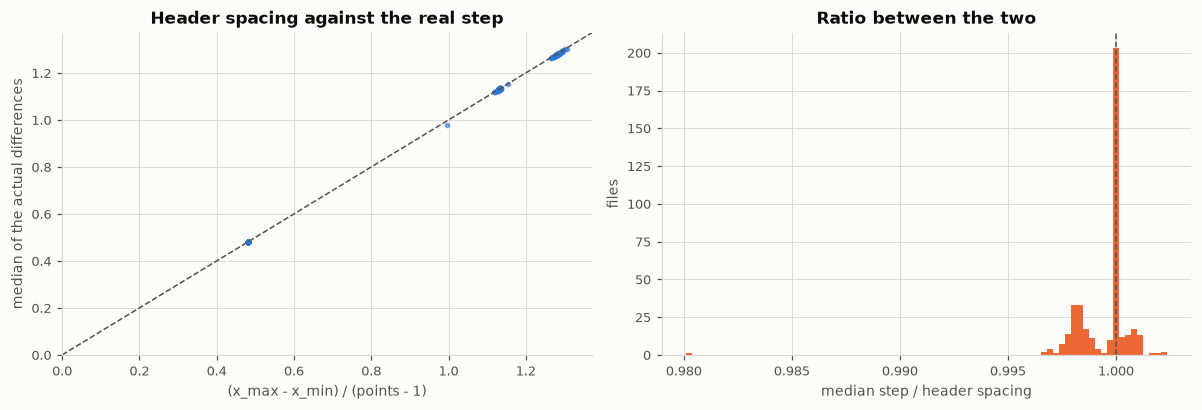

ratio: min 0.9801, median 1.0000, max 1.0024
files within 1% of a uniform grid: 399 of 400
points read in full against the header count, differing: 0


In [25]:
# The spacing in the header pass is (x_max - x_min) / (points - 1). Comparing it against the
# median of the actual differences shows whether the grid really is uniform.
check = quality.merge(
    kept[["name", "spacing", "points", "flatten_width"]], on="name",
    how="left", suffixes=("", "_header"),
)
check["ratio"] = check.median_step / check.spacing

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].scatter(check.spacing, check.median_step, s=7, color=BLUE, alpha=0.6)
limit = max(check.spacing.max(), check.median_step.max()) * 1.05
axes[0].plot([0, limit], [0, limit], color=INK_SOFT, lw=1, ls="--")
axes[0].set_xlim(0, limit)
axes[0].set_ylim(0, limit)
axes[0].set_xlabel("(x_max - x_min) / (points - 1)")
axes[0].set_ylabel("median of the actual differences")
axes[0].set_title("Header spacing against the real step")

axes[1].hist(check.ratio.dropna(), bins=80, color=ORANGE)
axes[1].axvline(1.0, color=INK_SOFT, lw=1, ls="--")
axes[1].set_xlabel("median step / header spacing")
axes[1].set_ylabel("files")
axes[1].set_title("Ratio between the two")
plt.tight_layout()
plt.show()

print(f"ratio: min {check.ratio.min():.4f}, median {check.ratio.median():.4f}, "
      f"max {check.ratio.max():.4f}")
print(f"files within 1% of a uniform grid: {int((check.ratio.sub(1).abs() < 0.01).sum()):,} "
      f"of {len(check):,}")
print(f"points read in full against the header count, differing: "
      f"{int((check.points != check.points_header).sum()):,}")

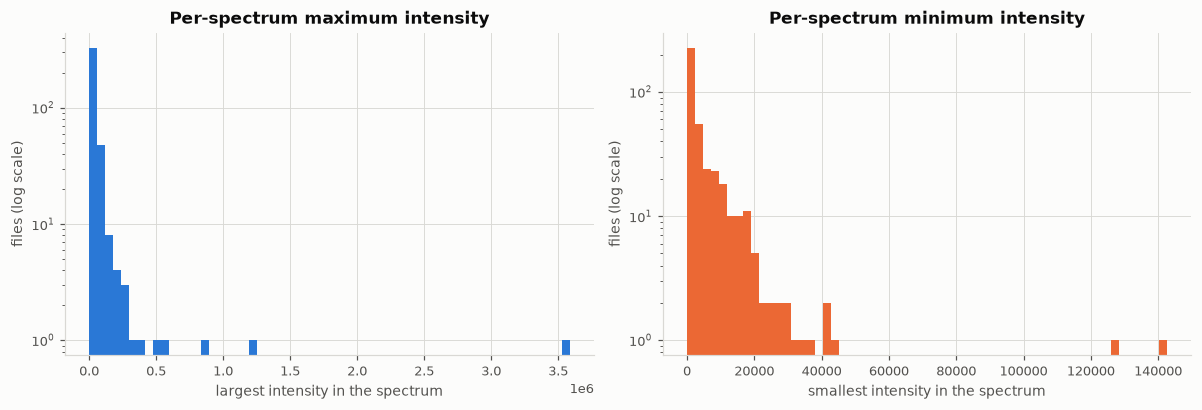

per-spectrum maximum intensity runs 5.384 to 3.586e+06, median 2.405e+04
per-spectrum minimum intensity runs -89.08 to 1.427e+05, median 1183
files with any negative intensity: 4 of 400
largest number of negatives in one spectrum: 1,111


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(quality.y_max, bins=60, color=BLUE)
axes[0].set_yscale("log")
axes[0].set_xlabel("largest intensity in the spectrum")
axes[0].set_ylabel("files (log scale)")
axes[0].set_title("Per-spectrum maximum intensity")

axes[1].hist(quality.y_min, bins=60, color=ORANGE)
axes[1].set_yscale("log")
axes[1].set_xlabel("smallest intensity in the spectrum")
axes[1].set_ylabel("files (log scale)")
axes[1].set_title("Per-spectrum minimum intensity")
plt.tight_layout()
plt.show()

print(f"per-spectrum maximum intensity runs {quality.y_max.min():.4g} to "
      f"{quality.y_max.max():.4g}, median {quality.y_max.median():.4g}")
print(f"per-spectrum minimum intensity runs {quality.y_min.min():.4g} to "
      f"{quality.y_min.max():.4g}, median {quality.y_min.median():.4g}")
print(f"files with any negative intensity: {int((quality.negatives > 0).sum()):,} "
      f"of {len(quality):,}")
print(f"largest number of negatives in one spectrum: {int(quality.negatives.max()):,}")

## 16. Unphysical values, over the whole kept set

Every kept file is read in full here, not a sample. Each check below is a value a Raman
spectrum cannot take, with the reason it cannot:

- **A shift below zero.** A Raman shift is measured from the laser line upwards, so a
  negative wavenumber is not a Stokes shift.
- **A shift at or past the laser's own wavenumber.** The scattered photon would then carry
  no energy: at 532 nm the laser line sits at 18,797 cm-1, so no shift can reach it. The
  limit is worked out per file from that file's own excitation wavelength.
- **An axis that does not strictly increase, or that repeats a value.** One wavenumber
  cannot carry two intensities, and an axis that walks backwards covers no single range.
- **A non-finite intensity.** NaN or infinity is not a count of photons.
- **A negative intensity.** A raw spectrum is a photon count, so it cannot be negative.
- **A spectrum with no variation at all.** The same value at every point measures nothing.
- **A row that is not two numbers.**

Three things are counted alongside the faults without being faults themselves: the laser
line sitting in the block at exactly zero, intensities that are all whole numbers, and a
largest intensity shared with another file.

In [27]:
def longest_identical_run(values):
    """The longest stretch of one value repeated at consecutive positions.

    Args:
        values (np.ndarray): the intensities of one spectrum.

    Returns:
        int: the number of positions in that stretch, 1 for a spectrum with no repeats
        and 0 for an empty one.
    """
    if values.size == 0:
        return 0
    same = (np.diff(values) == 0).astype(np.int8)
    edges = np.diff(np.concatenate(([0], same, [0])))
    starts = np.flatnonzero(edges == 1)
    ends = np.flatnonzero(edges == -1)
    return int((ends - starts).max()) + 1 if starts.size else 1


def scan_values(path, wavelength_nm):
    """Read one export in full and count the values a Raman spectrum cannot take.

    Args:
        path (Path): the export to read.
        wavelength_nm (float): its excitation wavelength, for the laser-line limit.

    Returns:
        dict: one entry per check holding the number of points that fail it, plus the
        file's own extremes and its pair count.
    """
    tokens = " ".join(read_block_rows(path)).replace(",", " ").replace("\t", " ").split()
    try:
        numbers = np.asarray(tokens, dtype=float)
        unparseable = 0
    except ValueError:
        # A token that will not convert is counted rather than dropped, so the parity of
        # the pairs it disturbs is visible in the result.
        kept_numbers = []
        unparseable = 0
        for token in tokens:
            try:
                kept_numbers.append(float(token))
            except ValueError:
                unparseable += 1
        numbers = np.asarray(kept_numbers, dtype=float)

    x = numbers[0::2]
    y = numbers[1::2]
    steps = np.diff(x)
    finite_x = x[np.isfinite(x)]
    finite_y = y[np.isfinite(y)]
    both_finite = np.isfinite(y).all() if y.size else False
    laser_limit = 1e7 / wavelength_nm if wavelength_nm == wavelength_nm else np.nan

    return {
        "pairs": int(y.size),
        "odd_tokens": int(numbers.size % 2),
        "unparseable": unparseable,
        "nonfinite": int((~np.isfinite(x)).sum() + (~np.isfinite(y)).sum()),
        "negative_x": int((x < 0).sum()),
        "rayleigh_x": int((x == 0).sum()),
        "beyond_laser": int((x >= laser_limit).sum()) if laser_limit == laser_limit else 0,
        "non_increasing_x": int((steps <= 0).sum()),
        "repeated_x": int((steps == 0).sum()),
        "negative_y": int((y < 0).sum()),
        "zero_y": int((y == 0).sum()),
        "constant": int(y.size > 0 and both_finite and y.max() == y.min()),
        "integer_y": int(y.size > 0 and both_finite and bool(np.all(y == np.round(y)))),
        "longest_run": longest_identical_run(y),
        "longest_nonzero_run": longest_identical_run(np.where(y == 0, np.nan, y)),
        "laser_fraction": (float(finite_x.max() / laser_limit)
                           if finite_x.size and laser_limit == laser_limit else np.nan),
        "x_min": float(finite_x.min()) if finite_x.size else np.nan,
        "x_max": float(finite_x.max()) if finite_x.size else np.nan,
        "y_min": float(finite_y.min()) if finite_y.size else np.nan,
        "y_max": float(finite_y.max()) if finite_y.size else np.nan,
    }

In [28]:
started = time.time()
records = []
for row in kept.itertuples():
    values = scan_values(Path(row.path), row.wavelength_nm)
    values["path"] = row.path
    records.append(values)

scan = pd.DataFrame.from_records(records)
by_path = kept.set_index("path")
# The header pass counted the lines it could read as two numbers. A file where the parsed
# pair count differs from that is a file whose rows were not read as intended.
scan["header_points"] = by_path.points.reindex(scan.path).values
scan["no_laser_limit"] = by_path.wavelength_nm.reindex(scan.path).isna().values

print(f"scanned {len(scan):,} kept files in full in {time.time() - started:.1f}s")
print(f"files whose parsed pairs differ from the header count: "
      f"{int((scan.pairs != scan.header_points).sum()):,}")
print(f"files with a token that is not a number: {int((scan.unparseable > 0).sum()):,}")
print(f"files whose data block does not split evenly into pairs: "
      f"{int((scan.odd_tokens > 0).sum()):,}")
print(f"files with no excitation wavelength, so no laser limit to check: "
      f"{int(scan.no_laser_limit.sum()):,}")

scanned 13,154 kept files in full in 12.1s
files whose parsed pairs differ from the header count: 0
files with a token that is not a number: 0
files whose data block does not split evenly into pairs: 0
files with no excitation wavelength, so no laser limit to check: 5


In [29]:
faults = [
    ("negative_x", "a wavenumber below zero"),
    ("beyond_laser", "a wavenumber at or past the laser line"),
    ("non_increasing_x", "a wavenumber not greater than the one before it"),
    ("repeated_x", "a wavenumber repeated at a second row"),
    ("nonfinite", "a non-finite wavenumber or intensity"),
    ("negative_y", "a negative intensity"),
    ("constant", "the same intensity at every point"),
]
fault_summary = pd.DataFrame({
    "files": [int((scan[column] > 0).sum()) for column, _ in faults],
    "points": [int(scan[column].sum()) for column, _ in faults],
}, index=[label for _, label in faults])
fault_summary["files_pct"] = (fault_summary.files / len(scan) * 100).round(2)

print(fault_summary.to_string())
print()
for label, value in {
    "files spanning the laser line at exactly zero": int((scan.rayleigh_x > 0).sum()),
    "files whose intensities are all whole numbers": int((scan.integer_y > 0).sum()),
    "files with at least one intensity of exactly zero": int((scan.zero_y > 0).sum()),
    "longest run of one repeated intensity anywhere": int(scan.longest_run.max()),
    "longest run of one repeated non-zero intensity anywhere": int(scan.longest_nonzero_run.max()),
    "files with a non-zero run of 50 identical intensities or more":
        int((scan.longest_nonzero_run >= 50).sum()),
}.items():
    print(f"  {value:7,d}  {label}")

                                                 files  points  files_pct
a wavenumber below zero                              4     164       0.03
a wavenumber at or past the laser line               0       0       0.00
a wavenumber not greater than the one before it      3    3939       0.02
a wavenumber repeated at a second row                3    3939       0.02
a non-finite wavenumber or intensity                 0       0       0.00
a negative intensity                               180   38459       1.37
the same intensity at every point                    0       0       0.00

        2  files spanning the laser line at exactly zero
      299  files whose intensities are all whole numbers
    1,230  files with at least one intensity of exactly zero
    1,282  longest run of one repeated intensity anywhere
       84  longest run of one repeated non-zero intensity anywhere
        2  files with a non-zero run of 50 identical intensities or more


In [30]:
joined = kept[["path", "archive"]].merge(scan, on="path")
joined["faults"] = joined[[column for column, _ in faults]].sum(axis=1)

print("files carrying at least one fault, by archive:")
print(pd.DataFrame({
    "files": joined.groupby("archive").size(),
    "with_a_fault": joined.groupby("archive")["faults"].apply(lambda s: int((s > 0).sum())),
}).to_string())
print()
print(f"kept files carrying at least one fault: {int((joined.faults > 0).sum()):,} "
      f"of {len(joined):,}")
print()
worst = joined.loc[joined.faults > 0].copy()
worst["name"] = worst.path.map(lambda path: Path(path).name)
worst.sort_values("faults", ascending=False)[
    ["archive", "name", "pairs", "faults", "non_increasing_x", "repeated_x",
     "negative_x", "nonfinite", "negative_y", "beyond_laser"]
].head(20)

files carrying at least one fault, by archive:
                      files  with_a_fault
archive                                  
excellent_oriented     3799             2
excellent_unoriented   5242            76
fair_oriented            12             0
fair_unoriented        1193            36
poor_unoriented         630            45
unrated_oriented       1927             0
unrated_unoriented      351            28

kept files carrying at least one fault: 187 of 13,154



,archive,name,pairs,faults,non_increasing_x,repeated_x,negative_x,nonfinite,negative_y,beyond_laser
6037,excellent_unoriented,Heflikite__R250030__Raman__532______Raman_Data...,3436,4194,2097,2097,0,0,0,0
4854,excellent_unoriented,Chromatite__R130086__Raman__532______Raman_Dat...,2522,3140,1570,1570,0,0,0,0
10417,poor_unoriented,Decrespignyite-(Y)__R060302__Raman__780______R...,2478,2466,0,0,0,0,2466,0
10590,poor_unoriented,Lavinskyite__R141115__Raman__780______Raman_Da...,2478,1882,0,0,0,0,1882,0
5151,excellent_unoriented,Diamond__R050205__Raman__780______Raman_Data_R...,2917,1801,0,0,0,0,1801,0
10534,poor_unoriented,Hammarite__R110028__Raman__532______Raman_Data...,2353,1768,0,0,0,0,1768,0
546,excellent_oriented,Atelisite-(Y)__R130043-3__Raman__514-5__90-000...,7966,1685,0,0,0,0,1685,0
10834,poor_unoriented,Tyrolite__R050571__Raman__780______Raman_Data_...,2478,1471,0,0,0,0,1471,0
10231,fair_unoriented,Zaratite__R050268__Raman__780______Raman_Data_...,2477,1457,0,0,0,0,1457,0
5798,excellent_unoriented,Getchellite__R060109__Raman__780______Raman_Da...,2478,1445,0,0,0,0,1445,0


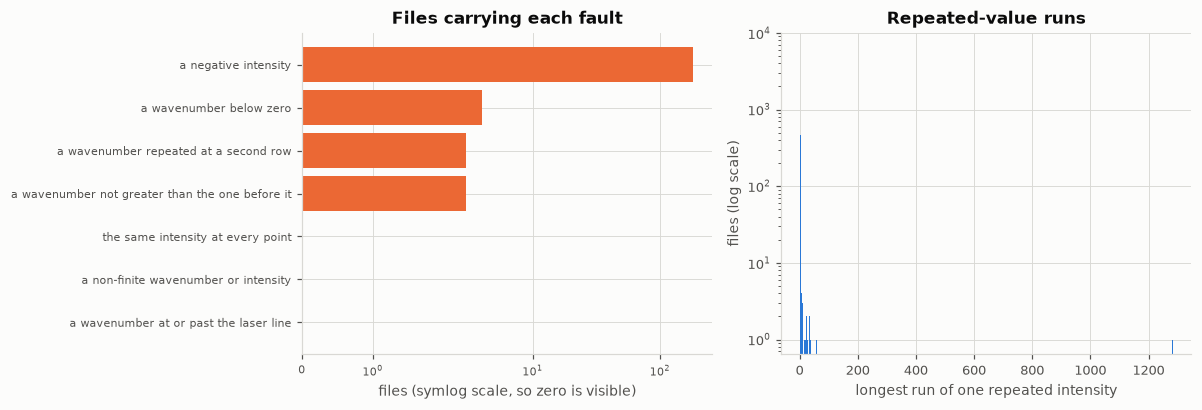

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
labels = [label for _, label in faults]
counts = [int((scan[column] > 0).sum()) for column, _ in faults]
order = np.argsort(counts)
axes[0].barh([labels[index] for index in order], [counts[index] for index in order], color=ORANGE)
axes[0].set_xscale("symlog")
axes[0].set_xlabel("files (symlog scale, so zero is visible)")
axes[0].set_title("Files carrying each fault")
axes[0].tick_params(labelsize=7.5)

axes[1].hist(scan.longest_run, bins=np.arange(1, int(scan.longest_run.max()) + 2), color=BLUE)
axes[1].set_yscale("log")
axes[1].set_xlabel("longest run of one repeated intensity")
axes[1].set_ylabel("files (log scale)")
axes[1].set_title("Repeated-value runs")
plt.tight_layout()
plt.show()

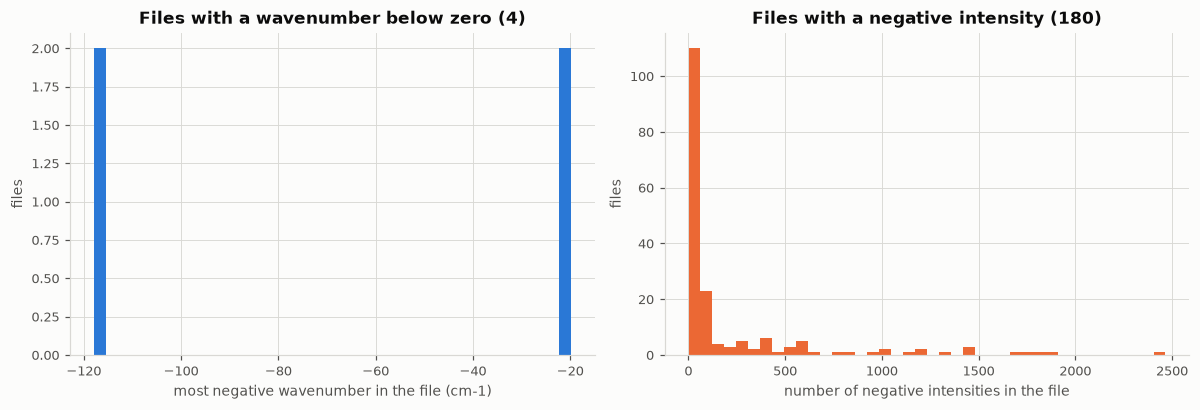

files with a wavenumber below zero: 4, most negative -117.908 cm-1, such points in total 164
files with a negative intensity: 180, most negative -1147, such points in total 38,459
files reaching the laser limit: 0; the furthest any file reaches is 0.429 of its own laser line's wavenumber
a repeated wavenumber is also a non-increase, so those two rows of the table above count the same points


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
below_zero = scan.loc[scan.negative_x > 0]
axes[0].hist(below_zero.x_min, bins=40, color=BLUE)
axes[0].set_xlabel("most negative wavenumber in the file (cm-1)")
axes[0].set_ylabel("files")
axes[0].set_title(f"Files with a wavenumber below zero ({len(below_zero):,})")

negative = scan.loc[scan.negative_y > 0]
axes[1].hist(negative.negative_y, bins=40, color=ORANGE)
axes[1].set_xlabel("number of negative intensities in the file")
axes[1].set_ylabel("files")
axes[1].set_title(f"Files with a negative intensity ({len(negative):,})")
plt.tight_layout()
plt.show()

print(f"files with a wavenumber below zero: {len(below_zero):,}, "
      f"most negative {scan.x_min.min():.3f} cm-1, "
      f"such points in total {int(scan.negative_x.sum()):,}")
print(f"files with a negative intensity: {len(negative):,}, "
      f"most negative {scan.y_min.min():.4g}, "
      f"such points in total {int(scan.negative_y.sum()):,}")
print(f"files reaching the laser limit: {int((scan.beyond_laser > 0).sum()):,}; "
      f"the furthest any file reaches is {scan.laser_fraction.max():.3f} of its own "
      f"laser line's wavenumber")
print("a repeated wavenumber is also a non-increase, so those two rows of the table above "
      "count the same points")

In [33]:
shared = scan.y_max.value_counts()
print(f"files whose largest intensity is shared with at least one other file: "
      f"{int(shared[shared > 1].sum()):,} of {len(scan):,}")
print()
print("most common per-file maximum intensities:")
for value, count in shared.head(10).items():
    print(f"  {int(count):6,d} files  {value:.6g}")
print()
print(f"largest intensity anywhere in the kept set: {scan.y_max.max():.6g}")
print(f"smallest of the per-file maxima:            {scan.y_max.min():.6g}")
print(f"most negative intensity anywhere:           {scan.y_min.min():.6g}")
print(f"files with a single distinct intensity:     {int(scan.constant.sum()):,}")

files whose largest intensity is shared with at least one other file: 1,562 of 13,154

most common per-file maximum intensities:
     119 files  65535
      94 files  65540
       5 files  59780
       5 files  53540
       5 files  49130
       4 files  57110
       4 files  59484
       4 files  46240
       4 files  52440
       4 files  50080

largest intensity anywhere in the kept set: 9.45821e+06
smallest of the per-file maxima:            0.761513
most negative intensity anywhere:           -1147.37
files with a single distinct intensity:     0


## 17. An example of each

One panel per value that the kept set actually contains, drawn from the file where it is
most extreme. Three of the checks in section 16 have nothing to draw, because they never
fire: no wavenumber at or past the laser line, no non-finite value, and no spectrum with a
single repeated intensity.

The spectrum is drawn in blue and every flagged value is marked in the alert colour, which
is used for nothing else: ringed where the marks are spaced out, solid where a long run of
them would otherwise overlap into a pale band. Three of the cases are faults and three are the counts that sit
alongside them in section 16.

In [34]:
import textwrap

from matplotlib.lines import Line2D

# Reserved for flagged values, so it never competes with a series colour. Checked against
# the spectrum blue: worst pair separation dE 26.7 under deuteranopia, 32.2 with normal
# vision, and both above 3:1 contrast on this surface.
FLAG = "#b3261e"

# A subtitle wrapped to this width stays inside its own panel instead of
# running into the panel beside it.
WRAP = 48

plot_index = kept[["path", "archive", "mineral", "rruff_id"]].merge(scan, on="path")

picked = set()


def choose(candidates, column, largest=True):
    """The most extreme file for one case, never one already drawn for another.

    Args:
        candidates (pd.DataFrame): the files that qualify for the case.
        column (str): the number the case is ranked on.
        largest (bool): True to take the largest value of that column, False the smallest.

    Returns:
        pd.Series: the row chosen.
    """
    remaining = candidates.loc[~candidates.path.isin(picked)]
    if remaining.empty:
        remaining = candidates
    row = remaining.sort_values(column, ascending=largest).iloc[-1]
    picked.add(row.path)
    return row


examples = {
    "wavenumber below zero": choose(plot_index.loc[plot_index.negative_x > 0], "x_min", largest=False),
    "axis not strictly increasing": choose(plot_index.loc[plot_index.non_increasing_x > 0],
                                           "non_increasing_x"),
    "negative intensity": choose(plot_index.loc[plot_index.negative_y > 0], "negative_y"),
    "intensity of exactly zero": choose(plot_index.loc[plot_index.zero_y > 0], "zero_y"),
    "longest repeated run": choose(plot_index.loc[plot_index.longest_nonzero_run >= 2],
                                   "longest_nonzero_run"),
    "largest intensity shared": choose(plot_index.loc[plot_index.y_max == 65535],
                                       "longest_nonzero_run"),
}

print("the file drawn for each case:")
print(pd.DataFrame([{
    "case": label,
    "mineral": row.mineral,
    "rruff_id": row.rruff_id,
    "archive": row.archive,
    "points": int(row.pairs),
    "below_zero": int(row.negative_x),
    "backwards": int(row.non_increasing_x),
    "negative_y": int(row.negative_y),
    "zeros": int(row.zero_y),
    "run_nonzero": int(row.longest_nonzero_run),
    "max": row.y_max,
} for label, row in examples.items()]).to_string(index=False))


def load_values(path):
    """The wavenumber and intensity columns of one export, for plotting.

    Args:
        path (Path): the export to read.

    Returns:
        tuple: the wavenumbers and the intensities, as arrays.
    """
    tokens = " ".join(read_block_rows(path)).replace(",", " ").replace("\t", " ").split()
    numbers = np.asarray(tokens, dtype=float)
    return numbers[0::2], numbers[1::2]


def longest_run_span(values):
    """Where the longest stretch of one repeated value sits.

    Args:
        values (np.ndarray): the intensities of one spectrum.

    Returns:
        tuple: the first and last position of that stretch, or None when no value repeats.
    """
    same = (np.diff(values) == 0).astype(np.int8)
    edges = np.diff(np.concatenate(([0], same, [0])))
    starts = np.flatnonzero(edges == 1)
    ends = np.flatnonzero(edges == -1)
    if not starts.size:
        return None
    longest = int(np.argmax(ends - starts))
    return int(starts[longest]), int(ends[longest])


def draw_spectrum(ax, x, y, flag, title, subtitle, y_label="intensity", ring=True,
                 marker=False):
    """One spectrum, with the flagged values marked so they are named as well as coloured.

    Args:
        ax: the axes to draw on.
        x, y (np.ndarray): the wavenumber and intensity columns.
        flag (np.ndarray): a mask of the values to mark, or None to mark nothing.
        title (str): the first title line.
        subtitle (str): the second title line, wrapped to WRAP so it stays in its panel.
        y_label (str): what the vertical axis measures.
        ring (bool): True to ring every mark in the surface colour, False for marks so
            dense and so exactly level with one another that the rings would cover the
            marks themselves rather than separate them.
        marker (bool): True to put a small marker on every row, for a panel where the
            rows themselves are what is being counted.
    """
    dots = ({"marker": "o", "markersize": 4.5, "markeredgecolor": SURFACE,
             "markeredgewidth": 0.6} if marker else {})
    ax.plot(x, y, color=BLUE, lw=1.3, zorder=2, **dots)
    if flag is not None and flag.any():
        if ring:
            ax.scatter(x[flag], y[flag], s=34, color=FLAG, edgecolor=SURFACE,
                       linewidth=0.8, zorder=3)
        else:
            ax.scatter(x[flag], y[flag], s=34, color=FLAG, linewidth=0, zorder=3)
    ax.set_title(f"{title}\n{textwrap.fill(subtitle, WRAP)}", fontsize=9, loc="left")
    ax.set_xlabel("wavenumber (cm-1)")
    ax.set_ylabel(y_label)


def even_titles(axes):
    """Give every panel in a row the same number of title lines.

    A panel whose subtitle wrapped to one line fewer would otherwise be drawn taller than
    its neighbours.

    Args:
        axes (np.ndarray): the axes of one figure.
    """
    flat = np.ravel(np.asarray(axes, dtype=object))
    titles = [ax.get_title() for ax in flat]
    tallest = max(text.count("\n") for text in titles)
    for ax, text in zip(flat, titles):
        if text.count("\n") < tallest:
            ax.set_title(text + "\n" * (tallest - text.count("\n")), fontsize=9, loc="left")


legend = [
    Line2D([], [], color=BLUE, lw=1.6, label="spectrum"),
    Line2D([], [], color=FLAG, marker="o", ls="none", markersize=7,
           markeredgecolor=SURFACE, label="flagged value"),
]

the file drawn for each case:
                        case            mineral rruff_id              archive  points  below_zero  backwards  negative_y  zeros  run_nonzero          max
       wavenumber below zero         Karlleuite  R250102   unrated_unoriented    1650          40          0           0      0            2  5214.733398
axis not strictly increasing          Heflikite  R250030 excellent_unoriented    3436           0       2097           0      0            6   823.000000
          negative intensity Decrespignyite-(Y)  R060302      poor_unoriented    2478           0          0        2466      0            1    10.168020
   intensity of exactly zero          Trevorite  R150038 excellent_unoriented    3984          42          0           0   1505            1  1093.739000
        longest repeated run            Edenite  R050415   excellent_oriented    1308           0          0           0      0           84 65535.000000
    largest intensity shared       Fluorapatit

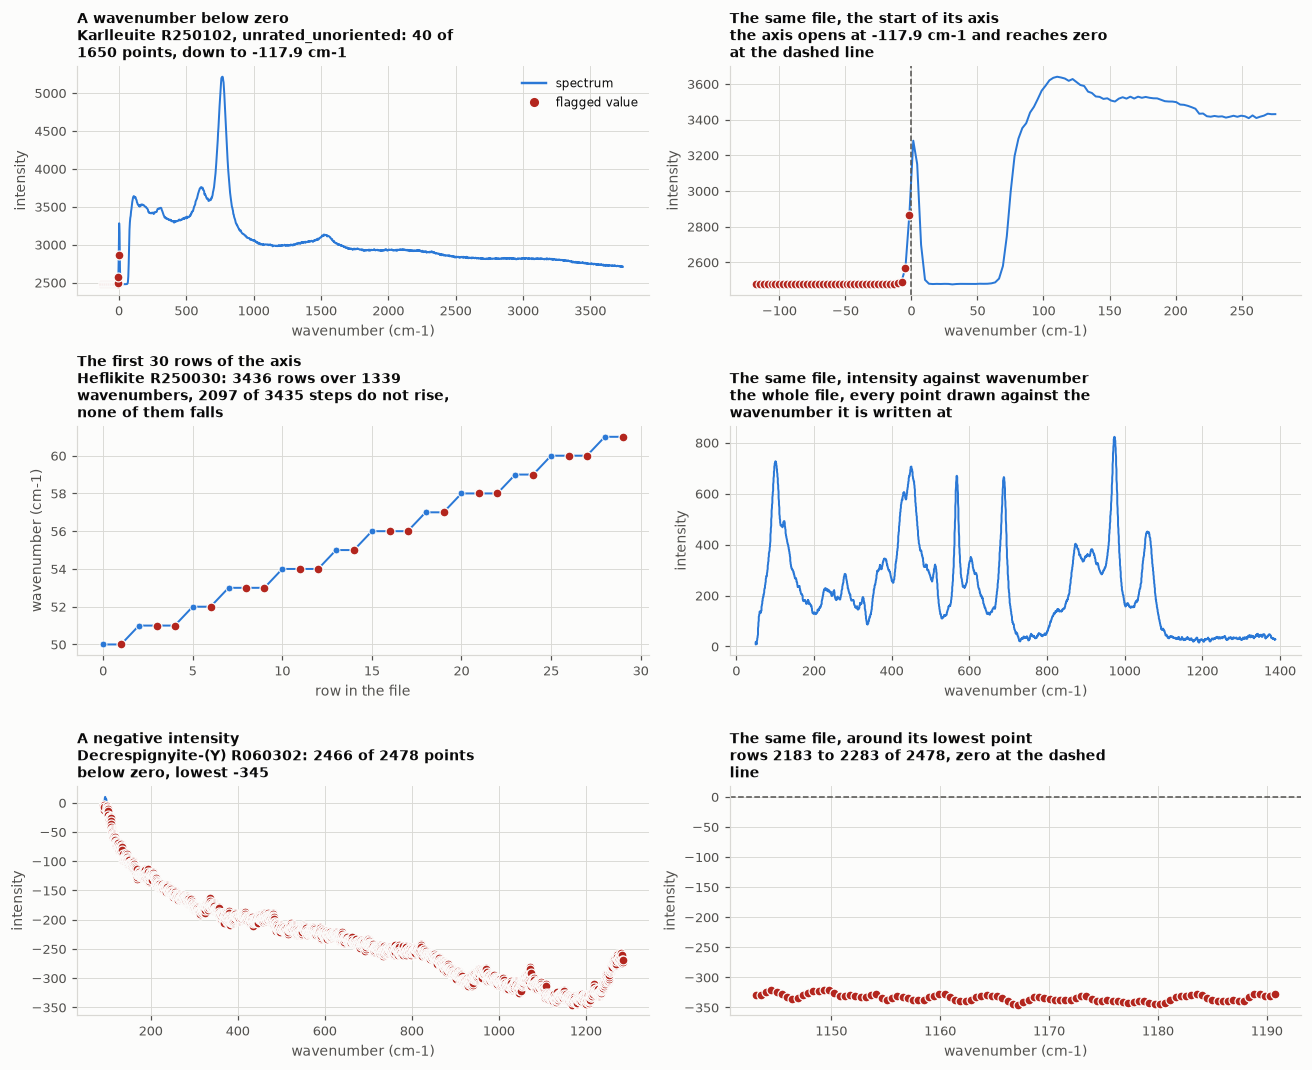

In [35]:
values = {label: load_values(Path(row.path)) for label, row in examples.items()}

# The three faults. Each fault gets the file whole, then the part of it that carries the
# problem, so the flagged values can be read against the rest of the spectrum.
row = examples["wavenumber below zero"]
x0, y0 = values["wavenumber below zero"]

fig, axes = plt.subplots(3, 2, figsize=(12, 9.8))
draw_spectrum(axes[0, 0], x0, y0, x0 < 0, "A wavenumber below zero",
              f"{row.mineral} {row.rruff_id}, {row.archive}: "
              f"{int(row.negative_x)} of {int(row.pairs)} points, down to {x0.min():.1f} cm-1")
axes[0, 0].legend(handles=legend, loc="upper right", fontsize=8)

start = x0.min() - 5
within = (x0 >= start) & (x0 <= start + 400)
draw_spectrum(axes[0, 1], x0[within], y0[within], (x0 < 0)[within],
              "The same file, the start of its axis",
              f"the axis opens at {x0.min():.1f} cm-1 and reaches zero at the dashed line")
axes[0, 1].axvline(0, color=INK_SOFT, lw=1, ls="--")

# A repeated wavenumber only shows in a short window. Across the whole file the line
# swings between the repeated value and the next one often enough to fill the panel.
row = examples["axis not strictly increasing"]
x1, y1 = values["axis not strictly increasing"]
steps = np.diff(x1)
falls = int(row.non_increasing_x) - int(row.repeated_x)
fall_text = "none of them falls" if falls == 0 else f"{falls} of them fall"
zoom = 30
draw_spectrum(axes[1, 0], np.arange(zoom), x1[:zoom],
              np.concatenate(([False], steps[:zoom - 1] == 0)),
              f"The first {zoom} rows of the axis",
              f"{row.mineral} {row.rruff_id}: {int(row.pairs)} rows over "
              f"{np.unique(x1).size} wavenumbers, {int(row.non_increasing_x)} of "
              f"{int(row.pairs) - 1} steps do not rise, {fall_text}",
              y_label="wavenumber (cm-1)", marker=True)
axes[1, 0].set_xlabel("row in the file")
draw_spectrum(axes[1, 1], x1, y1, None, "The same file, intensity against wavenumber",
              "the whole file, every point drawn against the wavenumber it is written at")

row = examples["negative intensity"]
x2, y2 = values["negative intensity"]
draw_spectrum(axes[2, 0], x2, y2, y2 < 0, "A negative intensity",
              f"{row.mineral} {row.rruff_id}: {int(row.negative_y)} of {int(row.pairs)} points "
              f"below zero, lowest {y2.min():.0f}")
centre = int(np.argmin(y2))
low, high = max(0, centre - 50), min(y2.size, centre + 50)
draw_spectrum(axes[2, 1], x2[low:high], y2[low:high], (y2 < 0)[low:high],
              "The same file, around its lowest point",
              f"rows {low} to {high} of {int(row.pairs)}, zero at the dashed line")
axes[2, 1].axhline(0, color=INK_SOFT, lw=1, ls="--")
even_titles(axes)
plt.tight_layout()
plt.show()


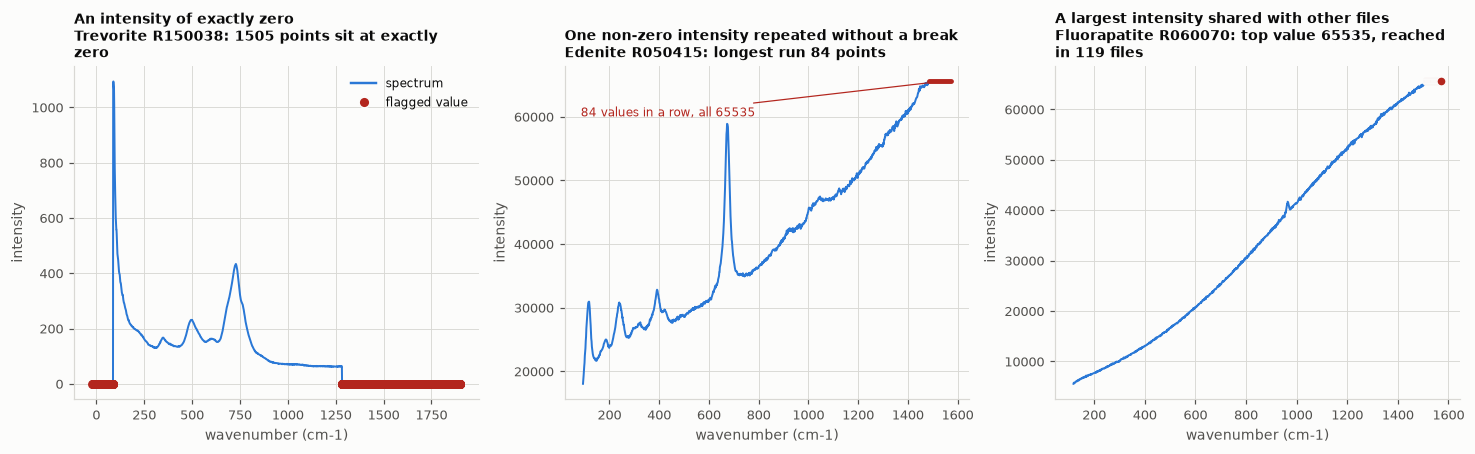

In [36]:
# The three counts that sit alongside the faults rather than being faults themselves.
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))

row = examples["intensity of exactly zero"]
x3, y3 = values["intensity of exactly zero"]
draw_spectrum(axes[0], x3, y3, y3 == 0, "An intensity of exactly zero",
              f"{row.mineral} {row.rruff_id}: {int(row.zero_y)} points sit at exactly zero",
              ring=False)
axes[0].legend(handles=legend, loc="upper right", fontsize=8)

row = examples["longest repeated run"]
x4, y4 = values["longest repeated run"]
draw_spectrum(axes[1], x4, y4, None, "One non-zero intensity repeated without a break",
              f"{row.mineral} {row.rruff_id}: longest run "
              f"{int(row.longest_nonzero_run)} points")
span = longest_run_span(np.where(y4 == 0, np.nan, y4))
if span is not None:
    first, last = span
    axes[1].plot(x4[first:last + 1], y4[first:last + 1], color=FLAG, lw=3.2, zorder=3,
                 solid_capstyle="round")
    # The run lies along the top edge of the panel, where a label placed above it would be
    # drawn over the title, so the label sits in the empty upper left and points across.
    axes[1].annotate(f"{last - first + 1} values in a row, all {y4[first]:.6g}",
                     xy=(x4[(first + last) // 2], y4[first]), xycoords="data",
                     xytext=(0.04, 0.86), textcoords="axes fraction",
                     ha="left", va="center", fontsize=8, color=FLAG,
                     arrowprops={"arrowstyle": "-", "color": FLAG, "lw": 0.8})

row = examples["largest intensity shared"]
x5, y5 = values["largest intensity shared"]
top = y5.max()
draw_spectrum(axes[2], x5, y5, y5 == top, "A largest intensity shared with other files",
              f"{row.mineral} {row.rruff_id}: top value {top:.0f}, reached in "
              f"{int((scan.y_max == top).sum())} files")
even_titles(axes)
plt.tight_layout()
plt.show()


## 18. The paper's own account of its training data

Nothing in this section is measured from the archives. It collects what the paper says about
how the training data for its CNN was built, read from the copy at
`~/Downloads/liu_et_al.pdf`, which is the preprint (arXiv:1708.09022v1, 18 August 2017) of

> J. Liu, M. Osadchy, L. Ashton, M. Foster, C. J. Solomon, S. J. Gibson, "Deep convolutional
> neural networks for Raman spectrum recognition: a unified solution", published in Analyst,
> 2017.

Every statement below is the paper's, and every number is one it prints.

**Two datasets, both from RRUFF.**

| Set | Preparation | Minerals | Spectra |
| --- | --- | --- | --- |
| Baseline corrected | "baseline corrected and cosmic rays have also been removed" | 1,671 | 5,168 |
| Raw | the exported spectrum, with no baseline correction | 512 | 1,676 |

The 1,671 and the 5,168 are stated in the results section for the first set and repeated in
Table 1 as "Ours #1". The 512 and the 1,676 come from Table 1 as "Ours #2"; the results section
for that set gives the mineral count only. Within the first set, a mineral holds between 1 and
40 spectra.

**The split is leave-one-out by mineral.** For a mineral with more than one spectrum, one is
drawn at random for testing and the rest are training data. The paper does not say what becomes
of a mineral that has only one spectrum. Table 2 is averaged over 50 independent runs of that
split, and the second set of experiments follows the same protocol.

**The imbalance is handled in the loss**, not by resampling: each training spectrum is weighted
by `1/#C`, where `#C` is the number of spectra in the class that spectrum belongs to.

**Three augmentation procedures**, described as a way to reduce the volume of data the CNN
needs:

1. every spectrum shifted left or right by a few wavenumbers, at random;
2. random noise added, proportional to the magnitude at each wavenumber;
3. for a mineral with more than one spectrum, a linear combination of its spectra, with the
   coefficients chosen at random.

**The input** is one dimensional and holds "the entire spectrum (intensity fully sampled at
regularly spaced wavenumbers)". The paper's figures draw spectra over 0 to 1600 cm-1 with
intensity from 0 to 1.

**How the data was used.** Adam for 50 epochs, learning rate 1e-3, beta1 0.9, beta2 0.999,
epsilon 1e-8. Weights initialised from a Gaussian with zero mean and variance 0.05. Batch
normalisation after every layer, dropout after the first fully connected layer, early stopping.
One GTX-1080, around seven hours.

**The accuracies reported on these sets.** Baseline corrected: top-1 0.884, top-3 0.953, top-5
0.963 (Table 2). Raw: top-1 0.933 (Table 3). The prose describing the first set reads "top-1
accuracy of 88.4% and top-3 accuracy of 96.3%", while Table 2 puts top-3 at 0.953 and top-5 at
0.963, so the prose figure matches the table's top-5.

**What the paper does not state**, which is what matters when matching this dataset to it:

- no excitation wavelength and no laser line, so nothing that says spectra from different
  excitation wavelengths were treated differently or kept apart;
- no RRUFF quality rating, so nothing that says excellent, fair, poor or unrated spectra were
  treated differently;
- no window, no spacing and no number of points for the input vector, beyond "regularly
  spaced", and so no flatten width to compare against section 10;
- no resampling or interpolation step, and no truncation of spectra to a common window;
- no intensity normalisation for the CNN input, although its own figures are drawn from 0 to 1;
- no file names, RRUFF IDs, or counts of RAW exports against Processed ones;
- the quality filtering the paper does mention, "spectra of bad quality which account for 80%
  of total amount", appears in a footnote to Table 1 as a feature of earlier work, not of the
  paper's own two sets.

The paper's own two sets cannot be recovered from the archives as they stand, since Table 1
gives no rule for which spectra were kept.


## 19. What this covers

| Section | Reports |
| --- | --- |
| 4 | how many files pass the RAW and confirmed filters, and what the dropped statuses say |
| 5 | wavelength range per archive and across the set, and how many files cover each candidate window |
| 6 | how many of each archive's files hold each wavenumber |
| 7 | the window that keeps the most files, and what a wider one costs |
| 8 | windows fixed by hand, and how much each file would have to be trimmed |
| 9 | spacing between points, per archive and per excitation wavelength |
| 10 | points per spectrum, and the flatten width implied by it |
| 11 | minerals per class, the spectra-per-mineral distribution, the largest classes |
| 12 | excitation wavelength, overall and within each archive |
| 13 | RAW and Processed exports of the same measurement |
| 14 | which archives contribute which minerals, and mineral overlap between archives |
| 15 | whether the grid is uniform, and the intensity scale |
| 16 | values a Raman spectrum cannot take, over the whole kept set |
| 17 | an example of each of those values, drawn from its most extreme file |
| 18 | what the paper states about its own training data, for comparison with the numbers above |
| 21 | the window the training data will use, and the reasoning behind the choice |

Section 18 is not measured from the archives: it is the paper's account of its own training data, kept beside the numbers above so the two can be read together.

Sections 5 to 10 bear on the open input questions: the window, the point count, and what a
kernel of 21, 11 or 5 points covers. Sections 11, 13 and 14 bear on how a split can be
drawn. Section 15 bears on whether the input needs scaling. The numbers are reported as
they stand.

Section 21 closes the notebook: it is the window decision this notebook was built to
reach, with the reasoning behind it as it was given.

## 20. Reproducing

```
cd /home/raj/projects/SH_Project
jupyter execute --inplace --kernel_name sh_project notebooks/raw_all.ipynb
```

The archives are read from `~/Desktop/raman_data`, or from `RRUFF_DATA` when that is set.
A full pass reads about 28,000 files.

## 21. The window the training data will use

The decision this notebook was built to reach, taking the numbers from section 8:

- **Which files.** A file joins the training set when its data reaches from 100 cm-1 or lower
  up to somewhere in 1250 to 1350 cm-1. That is 3,516 of the 13,154 kept files, 26.73%, holding
  1,290 minerals, 1,126 of them with two spectra or more.
- **Which data is kept.** The 0 to 1350 cm-1 span of each of those files. Anything below 0 cm-1
  is dropped there.
- **What the model sees.** Each file trimmed to 100 to 1250 cm-1. That set is the training data.

The reasoning, in the words it was given in:

> More data can be obtained for training if all of that data were used and trimmed to 100 - 1250cm-1 range. However, this would poor data as I believe that some minerals will exibit characteristic behaviour at the higher Raman shift that would be removed. I chose to go with 0 - 1350 cm-1 range as this allows me to keep the most amount of data files without losing too much information. I could calculate this more precisely by calculating the gradient of information (represented by the number files) and Raman shift but I am not doing that here (for now). I also think informaiton is dependent on not just the file count but resolution too. Also note that all of this is done without the consideration of excitation wavelength.

The notebook `notebooks/selected_data_eda.ipynb` carries this out from the
archives: it builds the trimmed set, reports where its spectra come from, and reports the
values in them that a Raman spectrum cannot take.
